<div style="font-size:25pt; line-height:25pt; font-weight:bold; text-align:center;">Détecter l'ivresse à partir de l'accéléromètre d'un smartphone</div>

# <a id="dim"></a> 1. INTRODUCTION

**Contexte.** Les épisodes d'alcoolisation massive exposent à des risques immédiats : accidents, comportements dangereux. Les interventions mobiles « juste à temps » supposent de détecter l'ivresse au moment où elle survient, sans action de l'utilisateur. Le smartphone, porté en permanence, offre pour cela un capteur passif : l'accéléromètre.

**Problématique.** Peut-on détecter, à partir de 10 secondes de signal d'accéléromètre, qu'une personne dépasse le seuil d'alcoolémie de 0,08 g/dl ?

**Hypothèse.** L'alcool altère la coordination motrice (équilibre, régularité de la marche). Cette altération doit laisser une trace dans le signal, au-delà du simple niveau d'activité.

**Démarche**

1. **Exploration** : qualité, couverture et cohérence des deux sources, accéléromètre et alcoolémie.
2. **Feature engineering** : nettoyage, découpage en fenêtres de 10 s étiquetées, calcul et normalisation des features.
3. **Apprentissage** : comparaison de quatre modèles.
4. **Réglage des hyperparamètres**, puis conclusion et pistes.

**Article de référence** : Killian et al., *Learning to Detect Heavy Drinking Episodes Using Smartphone Accelerometer Data* (2019), qui atteint 77,5 % d'accuracy avec une forêt aléatoire.

**Jeu de données**

- **13 participants** suivis pendant une tournée des bars (mai 2017), sur environ 24 heures.
- **Accéléromètre du téléphone** (11 iPhone, 2 Android), annoncé à 40 Hz : 14 millions de mesures (`time`, `pid`, `x`, `y`, `z`).
- **TAC** (*transdermal alcohol content*) : bracelet de cheville SCRAM, une mesure toutes les 30 minutes environ. Les fichiers `clean_tac` sont déjà lissés et décalés de 45 minutes, le délai de passage de l'alcool à travers la peau.
- **Target** : état d'ivresse si TAC ≥ 0,08 g/dl.

**Unités**

- `time` (accéléromètre) en millisecondes, `timestamp` (TAC) en secondes : deux horloges Unix, donc déjà alignées. Toutes les heures du notebook sont en UTC.
- `TAC_Reading` en g/dl. La limite légale de conduite, 0,08 g/dl, est retenue comme seuil d'ivresse.
- `x`, `y`, `z` : accélérations selon les axes du téléphone. Le README ne précise pas l'unité, qui diffère entre iPhone et Android (voir 2.2).

**Configuration** : librairies, chemin des données et constantes utilisées dans tout le notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, roc_auc_score)

In [2]:
# Chemin des données : Google Drive sur Colab, dossier "data" à côté du notebook en local
try:
    from google.colab import drive
    drive.mount('/content/drive')
    root = "/content/drive/MyDrive/data/"
except ImportError:
    root = "data/"

print("Données lues depuis :", root)

Données lues depuis : data/


In [3]:
SEUIL_TAC = 0.08        # g/dl : seuil d'ivresse retenu comme cible
FENETRE_MS = 10_000     # fenêtres de 10 s, comme dans l'article de référence
GAP_MS = 60_000         # un trou de plus d'1 min coupe un segment d'enregistrement

BLEU, ORANGE = '#2a78d6', '#eb6834'   # accéléromètre / TAC


def charger_tac(pid):
    """Mesures de TAC nettoyées d'un participant, triées par date."""
    return pd.read_csv(f"{root}clean_tac/{pid}_clean_TAC.csv").sort_values('timestamp')

# <a id="dim"></a> 2. EXPLORATION

## 2.1 Chargement des données

In [4]:
data_accelerometer = pd.read_csv(root + "all_accelerometer_data_pids_13.csv")
phone_data = pd.read_csv(root + "phone_types.csv")

data = pd.merge(data_accelerometer, phone_data, on='pid', how='inner')
print(f"{len(data)} lignes")
data.head()

14057567 lignes


,time,pid,x,y,z,phonetype
0,0,JB3156,0.0000,0.0000,0.0000,Android
1,0,CC6740,0.0000,0.0000,0.0000,Android
2,1493733882409,SA0297,0.0758,0.0273,-0.0102,iPhone
3,1493733882455,SA0297,-0.0359,0.0794,0.0037,iPhone
4,1493733882500,SA0297,-0.2427,-0.0861,-0.0163,iPhone


In [5]:
data.nunique()

time         12907011
pid                13
x             2940714
y             2729281
z             1328512
phonetype           2
dtype: int64

**14 millions de mesures, 13 participants, 2 marques de téléphone (iPhone, Android).**

## 2.2 Qualité des données

**Lignes à `time = 0`**

Les deux premières lignes (`time = 0`, `x = y = z = 0`), une par téléphone Android, ne sont pas des mesures : elles dateraient du 1er janvier 1970 et fausseraient tous les calculs de durée, on les a supprimées.

In [6]:
data = data[data['time'] > 0]
selected_pids = sorted(data['pid'].unique())

**Valeurs aberrantes**

Un accéléromètre de téléphone sature vers ±16 g : quelle que soit l'unité, une valeur au-delà de 200m.s-2 est physiquement impossible.

In [7]:
LIMITE = 200

hors_limite = (data[['x', 'y', 'z']].abs() > LIMITE).any(axis=1)

controle = data.groupby('pid')[['x', 'y', 'z']].agg(lambda s: s.abs().max()).add_prefix('max_abs_')
controle['lignes_aberrantes'] = hors_limite.groupby(data['pid']).sum()
controle['part_%'] = (100 * hors_limite.groupby(data['pid']).mean()).round(1)
controle['phonetype'] = data.groupby('pid')['phonetype'].first()

# Détail des lignes aberrantes : période concernée et valeurs prises par chaque axe
detail = data[hors_limite].groupby('pid').agg(
    debut=('time', 'min'), fin=('time', 'max'),
    x_min=('x', 'min'), x_max=('x', 'max'),
    y_min=('y', 'min'), y_max=('y', 'max'),
    z_min=('z', 'min'), z_max=('z', 'max'))
detail[['debut', 'fin']] = detail[['debut', 'fin']].apply(pd.to_datetime, unit='ms')

**Un seul participant touché, JB3156, dont près de la moitié du signal est inutilisable**

- **47 % de ses lignes** ont les axes y et z figés autour de ±180 millions, alors que l'axe x reste normal. Cela peut être une panne intermittente du capteur ou de l'application, pas un mouvement.
- **Les 12 autres participants** restent dans des bornes plausibles.

## 2.3 Mesures d'alcoolémie (TAC)

In [8]:
example_tac_clean = charger_tac('BK7610')
example_tac_raw = pd.read_excel(root + "raw_tac/BK7610 CAM Results.xlsx")

#display(example_tac_raw.head())
#display(example_tac_clean.head())

Le fichier brut (`raw_tac`) n'apporte rien d'exploitable pour la cible : colonnes sans label, date dupliquée, tension infrarouge et température. On travaille sur `clean_tac` : `timestamp` et `TAC_Reading`.

In [9]:
lignes = []
for pid in selected_pids:
    tac = charger_tac(pid)
    ecarts_min = tac['timestamp'].diff() / 60
    lignes.append({
        'pid': pid,
        'mesures': len(tac),
        'debut': pd.to_datetime(tac['timestamp'].min(), unit='s'),
        'fin': pd.to_datetime(tac['timestamp'].max(), unit='s'),
        'duree_h': round((tac['timestamp'].max() - tac['timestamp'].min()) / 3600, 1),
        'intervalle_median_min': round(ecarts_min.median(), 1),
        'intervalle_min_min': round(ecarts_min.min(), 1),
        'intervalles_<20min': int((ecarts_min < 20).sum()),
        'tac_min': round(tac['TAC_Reading'].min(), 3),
        'tac_max': round(tac['TAC_Reading'].max(), 3),
    })

resume_tac = pd.DataFrame(lignes).set_index('pid')
#display(resume_tac)

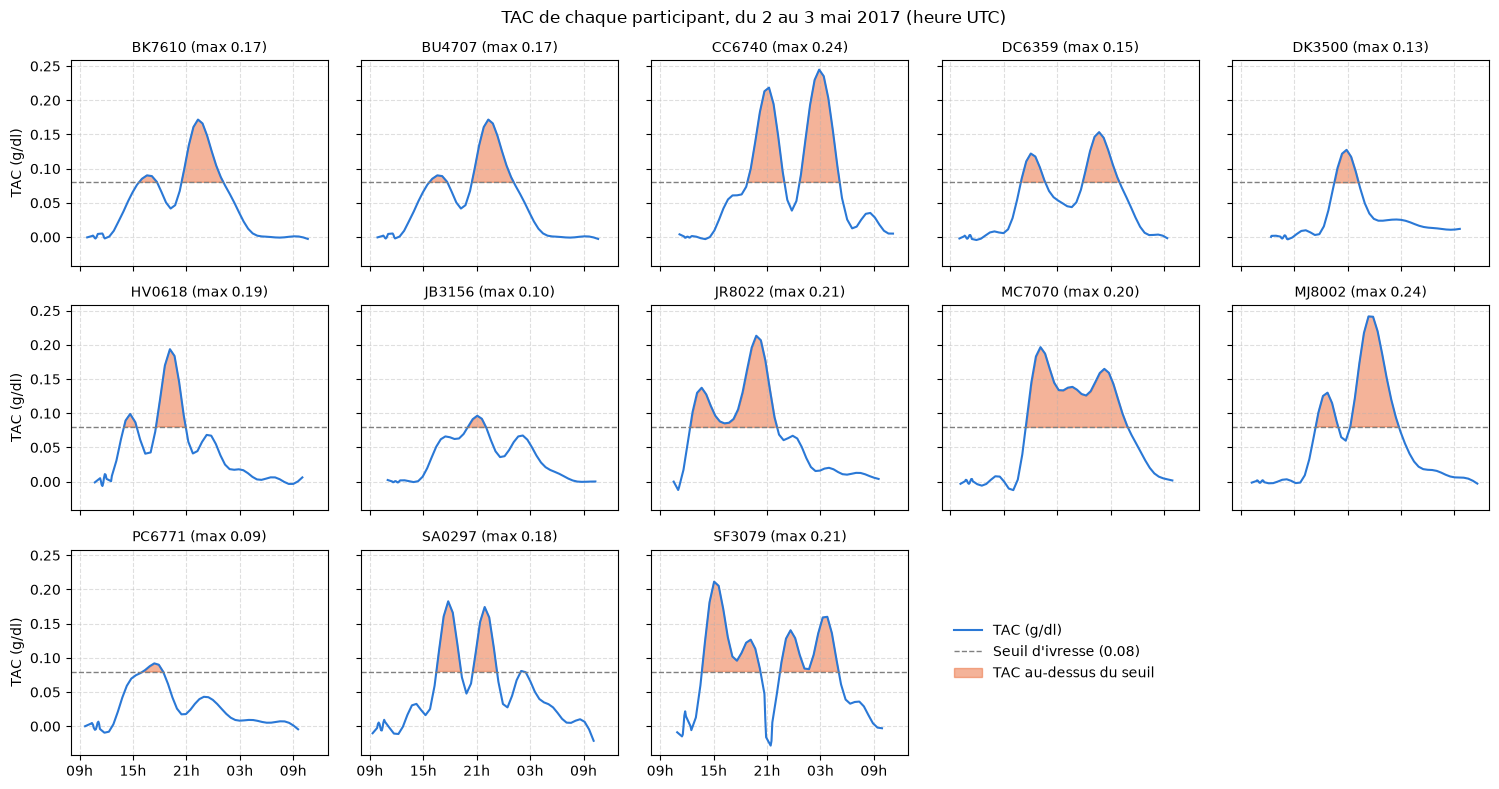

In [10]:
fig, axes = plt.subplots(3, 5, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.ravel()

for ax, pid in zip(axes, selected_pids):
    tac = charger_tac(pid)
    heure = pd.to_datetime(tac['timestamp'], unit='s')
    ax.plot(heure, tac['TAC_Reading'], color=BLEU, linewidth=1.5)
    ax.fill_between(heure, SEUIL_TAC, tac['TAC_Reading'], where=tac['TAC_Reading'] >= SEUIL_TAC,
                    interpolate=True, color=ORANGE, alpha=0.5)
    ax.axhline(SEUIL_TAC, color='gray', linestyle='--', linewidth=1)
    ax.set_title(f"{pid} (max {tac['TAC_Reading'].max():.2f})", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Hh'))

# Les deux cases libres servent de légende
for ax in axes[len(selected_pids):]:
    ax.axis('off')
axes[-2].plot([], [], color=BLEU, linewidth=1.5, label='TAC (g/dl)')
axes[-2].plot([], [], color='gray', linestyle='--', linewidth=1, label=f'Seuil d\'ivresse ({SEUIL_TAC})')
axes[-2].fill_between([], [], [], color=ORANGE, alpha=0.5, label='TAC au-dessus du seuil')
axes[-2].legend(loc='center left', frameon=False)

fig.suptitle('TAC de chaque participant, du 2 au 3 mai 2017 (heure UTC)')
for ax in axes[::5]:
    ax.set_ylabel('TAC (g/dl)')
plt.tight_layout()
plt.show()

**Tous les participants dépassent le seuil, mais très inégalement**

- **TAC maximal de 0,09 à 0,24 g/dl** : certains franchissent à peine le seuil, d'autres restent au-dessus plus de 11 heures.
- **La plupart des courbes ont deux pics** (après-midi et soirée), et toutes partent de 0 pour y revenir : le bracelet couvre l'épisode complet.
- **Conséquence** : le temps passé en état d'ivresse varie fortement d'un participant à l'autre, ce qui annonce des classes très déséquilibrées selon les personnes.

- **BK7610 et BU4707 ont exactement le même fichier TAC**, alors que leurs signaux d'accéléromètre diffèrent : l'un des deux porte des étiquettes qui ne sont pas les siennes, on supprimera le participant avec le moins de données (3.1).

## 2.4 Fréquence d'échantillonnage de l'accéléromètre

In [11]:
lignes = []
for pid in selected_pids:
    acc = data[data['pid'] == pid]
    ecarts_ms = acc['time'].sort_values().diff()
    ecarts_ms = ecarts_ms[ecarts_ms > 0]
    lignes.append({
        'pid': pid,
        'phonetype': acc['phonetype'].iloc[0],
        'mesures': len(acc),
        'ecart_median_ms': ecarts_ms.median(),
        'frequence_hz': round(1000 / ecarts_ms.median(), 1),
    })

echantillonnage = pd.DataFrame(lignes).set_index('pid').sort_values('frequence_hz')
#display(echantillonnage)

**La fréquence annoncée de 40 Hz n'est pas respectée par tous les téléphones**

- **La plupart des téléphones sont à 40 Hz**, mais la fréquence va de 22 Hz à 50 Hz.
- Des paquets d'un nombre fixe de mesures couvriraient de 8 à 18 s selon le téléphone, donc on va découper le signal en fenêtres de durée fixe.

## 2.5 Couverture temporelle : accéléromètre et TAC

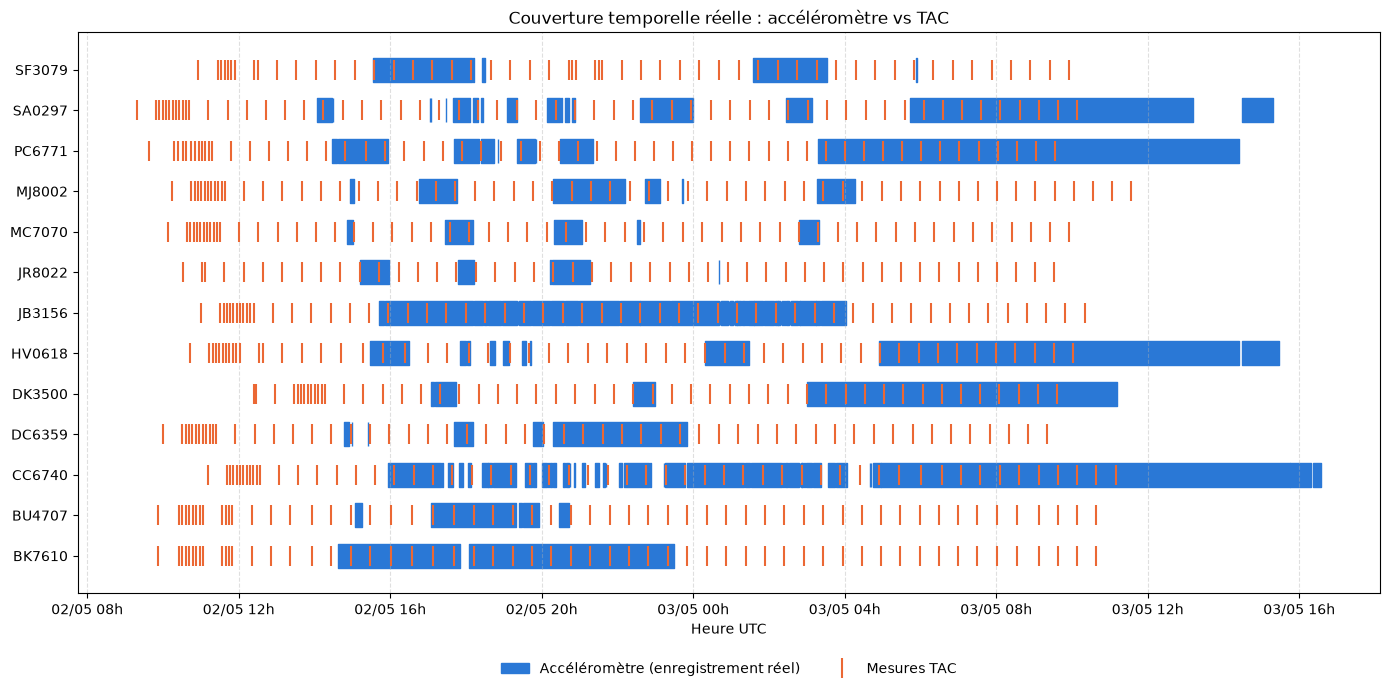

In [12]:
fig, ax = plt.subplots(figsize=(14, 7))
for i, pid in enumerate(selected_pids):
    # Accéléromètre : segments réellement enregistrés
    t = data.loc[data['pid'] == pid, 'time'].sort_values()
    segments = t.groupby((t.diff() > GAP_MS).cumsum()).agg(['min', 'max'])
    # Un axe de dates matplotlib compte en jours : on convertit début et fin avec date2num
    debut = mdates.date2num(pd.to_datetime(segments['min'], unit='ms'))
    fin = mdates.date2num(pd.to_datetime(segments['max'], unit='ms'))
    ax.broken_barh(list(zip(debut, fin - debut)), (i - 0.3, 0.6), color=BLEU,
                   label='Accéléromètre (enregistrement réel)' if i == 0 else None)

    # TAC : un trait par mesure
    tac = charger_tac(pid)
    ax.plot(pd.to_datetime(tac['timestamp'], unit='s'), [i] * len(tac), '|', color=ORANGE,
            markersize=14, markeredgewidth=1.5, label='Mesures TAC' if i == 0 else None)

ax.set_yticks(range(len(selected_pids)))
ax.set_yticklabels(selected_pids)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %Hh'))
ax.set_xlabel('Heure UTC')
ax.set_title('Couverture temporelle réelle : accéléromètre vs TAC')
ax.grid(True, axis='x', linestyle='--', alpha=0.4)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

**Des enregistrements discontinus, qui ne couvrent qu'une partie du suivi TAC**

- **Le TAC couvre 21 à 25 heures ; l'accéléromètre n'enregistre réellement que 2 à 16 heures par participant**, avec des trous allant jusqu'à 7 heures. 
- **L'accéléromètre démarre toujours plusieurs heures après le TAC**, et chez 5 participants il continue après la dernière mesure TAC : on ne gardera que les mesures situées dans la période de suivi TAC (3.1).

On mesure le temps de signal disponible en découpant chaque enregistrement en fenêtres de 10 s :

In [13]:
def fenetres_10s(pid):
    """Fenêtres de 10 s d'un participant situées dans sa période de suivi TAC.

    Colonnes : n (nombre de mesures), t (instant moyen, en ms), remplissage (n rapporté au
    nombre attendu d'après la fréquence du téléphone) et tac (TAC interpolé à l'instant t).
    """
    acc = data[data['pid'] == pid].sort_values('time')
    tac = charger_tac(pid)
    attendu = FENETRE_MS / acc['time'].diff().median()
    fen = acc.groupby(acc['time'] // FENETRE_MS).agg(n=('time', 'size'), t=('time', 'mean'))
    fen['remplissage'] = fen['n'] / attendu
    fen['tac'] = np.interp(fen['t'] / 1000, tac['timestamp'], tac['TAC_Reading'])
    return fen[(fen['t'] / 1000).between(tac['timestamp'].min(), tac['timestamp'].max())]


lignes = []
for pid in selected_pids:
    fen = fenetres_10s(pid)
    fen = fen[fen['remplissage'] >= 0.5]          # fenêtres au moins à moitié remplies
    ivre = fen['tac'] >= SEUIL_TAC
    lignes.append({
        'pid': pid,
        'tac_max': charger_tac(pid)['TAC_Reading'].max(),
        'heures_utilisables': len(fen) / 360,     # 360 fenêtres de 10 s par heure
        'heures_sobre': (~ivre).sum() / 360,
        'heures_ivre': ivre.sum() / 360,
    })

classes = pd.DataFrame(lignes).set_index('pid').sort_values('heures_ivre', ascending=False)
classes.loc['Total'] = classes.sum()
classes.loc['Total', 'tac_max'] = np.nan
classes['part_ivre_%'] = 100 * classes['heures_ivre'] / classes['heures_utilisables']
display(classes.round(2))

,tac_max,heures_utilisables,heures_sobre,heures_ivre,part_ivre_%
pid,,,,,
BK7610,0.17,8.53,3.52,5.01,58.70
SF3079,0.21,4.62,0.01,4.62,99.88
CC6740,0.24,11.22,8.69,2.52,22.49
JR8022,0.21,2.14,0.01,2.13,99.48
MC7070,0.20,2.22,0.16,2.07,93.00
SA0297,0.18,8.27,6.60,1.67,20.18
MJ8002,0.24,4.38,2.73,1.65,37.71
JB3156,0.10,6.68,5.41,1.28,19.12
BU4707,0.17,3.11,2.21,0.90,29.02


**81 heures de signal étiquetable, dont 29 % en état d'ivresse, très inégalement réparties**

- **Seuls 5 participants ont plus d'une heure dans chaque classe** : ce sont les seuls où l'on observe la transition sobre/ivre chez une même personne.
- **4 participants n'ont qu'une seule classe** : 3 presque uniquement ivres, 1 uniquement sobre, son épisode d'ivresse tombant dans un trou d'enregistrement. Les 3 participants « ivres » fournissent pourtant plus d'un tiers de la classe ivre.
- Un modèle pourrait reconnaître la personne plutôt que son état, on évaluera **participant par participant**.

## 2.6 Signal de l'accéléromètre : l'exemple de BK7610

BK7610, dont l'enregistrement est presque continu et couvre plusieurs heures dans chaque classe, sert d'exemple pour observer le signal de près.

In [14]:
data_bk7610 = data[data['pid'] == 'BK7610'].sort_values('time').copy()
#data_bk7610[['x', 'y', 'z']].describe()

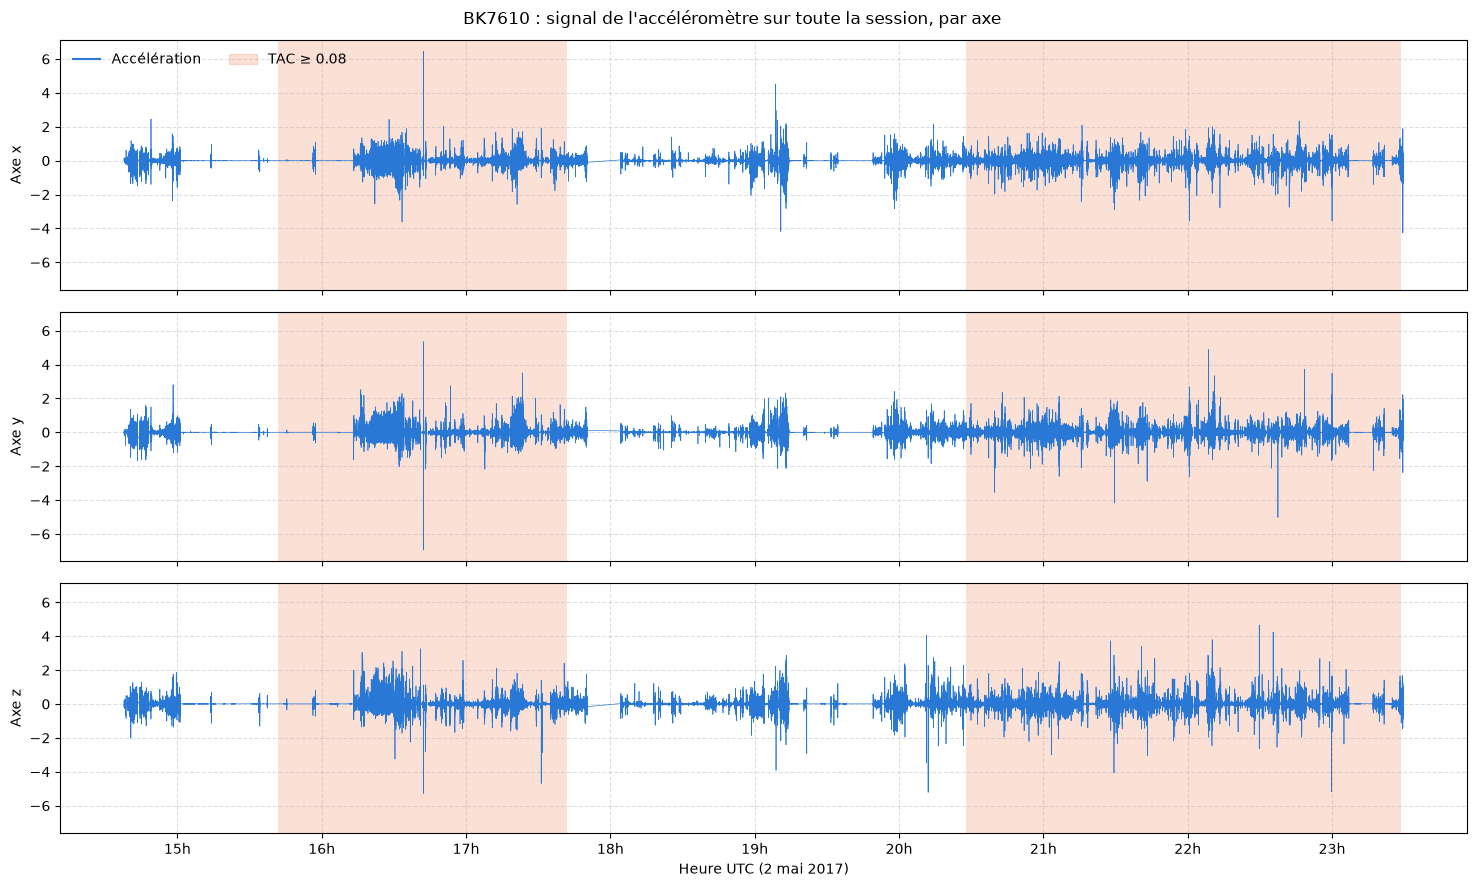

In [15]:
tac_bk = example_tac_clean
heure_acc = pd.to_datetime(data_bk7610['time'], unit='ms')

# TAC interpolé minute par minute, pour colorer les périodes au-dessus du seuil
grille = np.arange(data_bk7610['time'].min(), data_bk7610['time'].max(), 60_000)
ivre = np.interp(grille / 1000, tac_bk['timestamp'], tac_bk['TAC_Reading']) >= SEUIL_TAC
heure_grille = pd.to_datetime(grille, unit='ms')

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True, sharey=True)
for ax, axe in zip(axes, ['x', 'y', 'z']):
    ax.plot(heure_acc, data_bk7610[axe], color=BLEU, linewidth=0.5)
    ax.fill_between(heure_grille, 0, 1, where=ivre, transform=ax.get_xaxis_transform(),
                    color=ORANGE, alpha=0.2, linewidth=0)
    ax.set_ylabel(f'Axe {axe}')
    ax.grid(True, linestyle='--', alpha=0.4)

axes[0].plot([], [], color=BLEU, label='Accélération')
axes[0].fill_between([], [], [], color=ORANGE, alpha=0.2, label=f'TAC ≥ {SEUIL_TAC}')
axes[0].legend(loc='upper left', ncol=2, frameon=False)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Hh'))
axes[-1].set_xlabel('Heure UTC (2 mai 2017)')
fig.suptitle("BK7610 : signal de l'accéléromètre sur toute la session, par axe")
plt.tight_layout()
plt.show()

**Le niveau d'activité ne suit pas le TAC**

- **Le signal alterne phases d'activité et phases plates** (téléphone posé ou participant immobile). Les trois axes bougent ensemble : sans orientation connue du téléphone, on ne peut pas associer un axe à une direction.
- **Les périodes au-dessus du seuil contiennent aussi bien du signal plat que des phases très actives**, et des phases actives existent sous le seuil.

TAC bas (< 0,06) : 630 fenêtres, agitation médiane 0.013
TAC élevé (≥ 0,15) : 605 fenêtres, agitation médiane 0.066


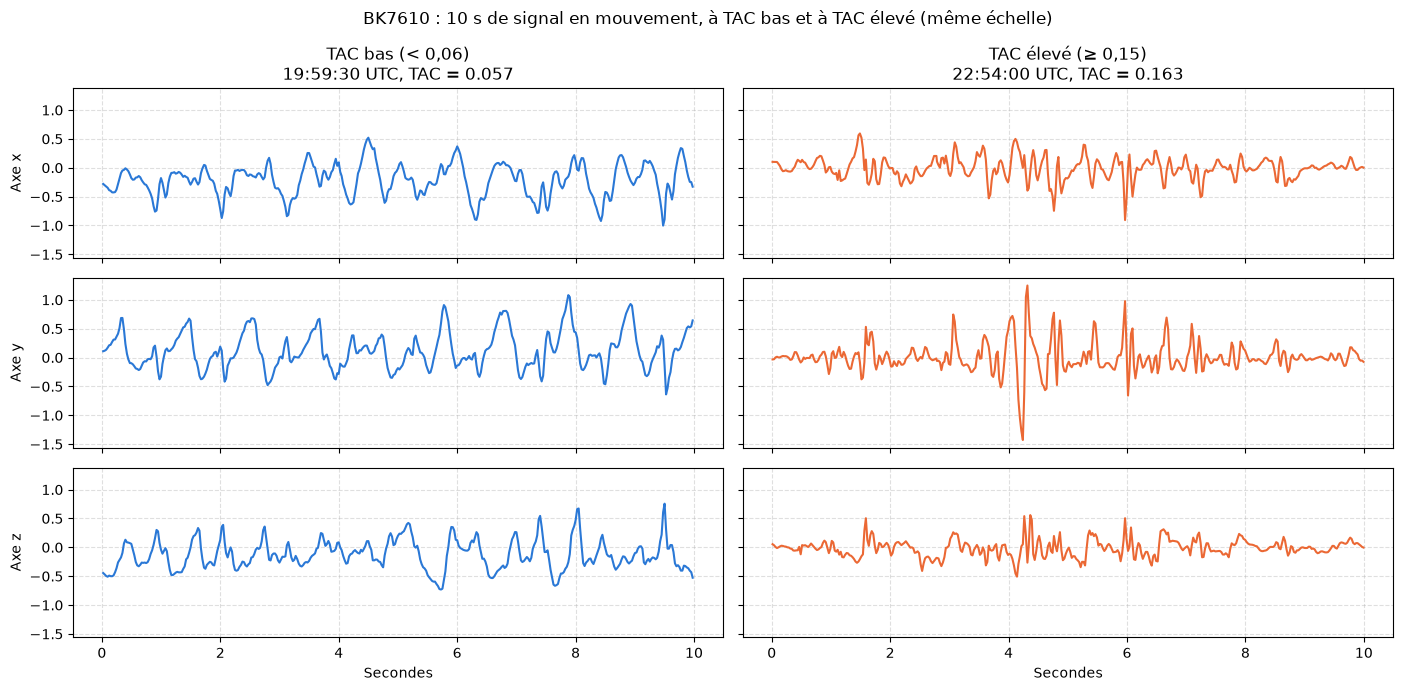

In [16]:
# 10 secondes de signal à TAC bas et à TAC élevé
# (pendant l'enregistrement, le TAC de BK7610 ne descend jamais sous 0,04 : pas de période vraiment sobre)
fen = fenetres_10s('BK7610')
fen = fen[fen['remplissage'] >= 0.95].copy()             # fenêtres complètes uniquement

# Niveau d'agitation de chaque fenêtre : écart-type de la magnitude du signal
magnitude = np.sqrt(data_bk7610['x']**2 + data_bk7610['y']**2 + data_bk7610['z']**2)
fen['agitation'] = magnitude.groupby(data_bk7610['time'] // FENETRE_MS).std()

etats = {'TAC bas (< 0,06)': (fen[fen['tac'] < 0.06], BLEU),
         'TAC élevé (≥ 0,15)': (fen[fen['tac'] >= 0.15], ORANGE)}

# Dans chaque état, on prend une fenêtre "en mouvement" : celle dont l'agitation est
# la plus proche du 90e centile de l'état (ni un téléphone posé, ni un pic extrême)
fig, axes = plt.subplots(3, 2, figsize=(14, 7), sharex=True, sharey=True)
for col, (titre, (f, couleur)) in enumerate(etats.items()):
    choix = (f['agitation'] - f['agitation'].quantile(0.9)).abs().idxmin()
    w = data_bk7610[data_bk7610['time'] // FENETRE_MS == choix]
    secondes = (w['time'] - choix * FENETRE_MS) / 1000
    heure = pd.to_datetime(choix * FENETRE_MS, unit='ms').strftime('%H:%M:%S')
    for lig, axe in enumerate(['x', 'y', 'z']):
        ax = axes[lig, col]
        ax.plot(secondes, w[axe], color=couleur, linewidth=1.5)
        ax.grid(True, linestyle='--', alpha=0.4)
        if col == 0:
            ax.set_ylabel(f'Axe {axe}')
    axes[0, col].set_title(f"{titre}\n{heure} UTC, TAC = {f.loc[choix, 'tac']:.3f}")
    axes[2, col].set_xlabel('Secondes')
    print(f"{titre} : {len(f)} fenêtres, agitation médiane {f['agitation'].median():.3f}")

fig.suptitle('BK7610 : 10 s de signal en mouvement, à TAC bas et à TAC élevé (même échelle)')
plt.tight_layout()
plt.show()

**À TAC bas et à TAC élevé, on a la même amplitude mais une allure différente**

- **BK7610 n'est jamais vraiment sobre** pendant l'enregistrement : la comparaison porte sur un TAC bas et un TAC élevé.
- **L'amplitude est identique** dans les deux états. La différence visible porte sur la **régularité** : oscillations régulières, comme une marche, à TAC bas ; mouvements par à-coups à TAC élevé.

## 2.7 Bilan de l'exploration

- **Volume** : 14 millions de mesures d'accéléromètre et 715 mesures de TAC pour 13 participants, soit environ 80 heures de signal étiquetable, dont 29 % en état d'ivresse.
- **Données imparfaites** : panne de capteur chez JB3156, fichier TAC dupliqué entre BK7610 et BU4707, fréquences de 22 à 50 Hz, échelle d'accélération 10 à 100 fois plus grande sur Android, enregistrements discontinus.

# <a id="dim"></a> 3. FEATURE ENGINEERING

**Objectifs** : 
1. **Nettoyage** des anomalies repérées à l'exploration.
2. **Construction des échantillons** : fenêtres de 10 s et étiquetage.
3. **Calcul des features** : temporelles, spectrales, puis relations entre axes et contexte.
4. **Normalisation** par participant.
5. **Analyse des features** : redondance et pouvoir de séparation.

## 3.1 Nettoyage des données

Pendant l'exploration, on a identifié trois corrections :

- **Panne de capteur de JB3156** : retrait des lignes aux axes y et z figés.
- **TAC dupliqué** : BU4707 est retiré ; BK7610, qui a près de trois fois plus de données, est conservé.
- **Mesures hors du suivi TAC** : retirées, faute d'étiquette.

In [17]:
#Drop des valeurs aberrantes de l'accélèromètre : 
data = data[(data['x'].abs() < LIMITE) & (data['y'].abs() < LIMITE) & (data['z'].abs() < LIMITE)]
print(f"{len(data)} lignes")

13500518 lignes


In [18]:
# BK7610 et BU4707 ont exactement le même fichier TAC (voir 2.3) : l'un des deux a des étiquettes
# qui ne sont pas les siennes. On garde BK7610, qui a près de trois fois plus de données, et on retire BU4707.
data = data[data['pid'] != 'BU4707']
selected_pids = [pid for pid in selected_pids if pid != 'BU4707']
print(f"{len(data)} lignes, {len(selected_pids)} participants")

13053095 lignes, 12 participants


In [19]:
# On ne garde que les mesures d'accéléromètre situées entre la première et la dernière mesure TAC
# du participant : en dehors de cette période, on ne peut pas leur attribuer d'étiquette.
bornes_tac = pd.DataFrame({pid: charger_tac(pid)['timestamp'].agg(['min', 'max']) * 1000
                           for pid in selected_pids}).T      # en ms, comme data['time']
debut_tac = data['pid'].map(bornes_tac['min'])
fin_tac = data['pid'].map(bornes_tac['max'])

avant = data.groupby('pid').size()
data = data[(data['time'] >= debut_tac) & (data['time'] <= fin_tac)]

bilan = pd.DataFrame({'avant': avant, 'après': data.groupby('pid').size()})
bilan['retirées'] = bilan['avant'] - bilan['après']
bilan['part_conservée_%'] = (100 * bilan['après'] / bilan['avant']).round(1)
#display(bilan)
print(f"{bilan['retirées'].sum()} lignes retirées, {len(data)} lignes conservées")

2679159 lignes retirées, 10373936 lignes conservées


**Le retrait le plus important vient du suivi TAC** (20 % des mesures restantes). Il se situe toujours en fin de session, quand le TAC est revenu à 0 : seule la classe sobre, majoritaire, est touchée.
On conserve **10,4 millions de mesures pour 12 participants**

## 3.2 Construction des échantillons : fenêtres de 10 s

**Objectif** : faire de chaque fenêtre de 10 s un exemple d'apprentissage.

Une mesure isolée ne dit rien du mouvement, qui se lit dans la forme du signal sur une durée.
Les téléphones enregistrent de 22 à 50 Hz donc un découpage par durée garantit que chaque ligne décrit la même tranche de temps. On choisit 10s, la durée de l'article de référence, assez longue pour contenir plusieurs pas, assez courte pour que le TAC soit quasi constant. Ce choix est discuté en section 5.

En prenant une fenêtre de 10s, on pourrait avoir un trou dans l'enregistrement donc on choisit de fixer un seuil de remplissage à 80% : la fenêtre est conservée si au moins 80% des mesures attendues pour le téléphone sont faites.

In [20]:
REMPLISSAGE_MIN = 0.8   # part minimale des mesures attendues pour garder une fenêtre

# 1. Chaque mesure reçoit le numéro de sa fenêtre de 10 s et sa magnitude
data = data.sort_values(['pid', 'time']).assign(
    fenetre=lambda d: d['time'] // FENETRE_MS,
    magnitude=lambda d: np.sqrt(d['x']**2 + d['y']**2 + d['z']**2))

# 2. Une ligne par fenêtre : nombre de mesures et instant moyen (en ms)
fenetres = data.groupby(['pid', 'fenetre']).agg(n=('time', 'size'), t=('time', 'mean'))

# 3. Remplissage : nombre de mesures rapporté au nombre attendu pour ce téléphone,
#    calculé à partir de son écart médian entre deux mesures (20, 25, 26 ou 45 ms)
ecart_median_ms = data.groupby('pid')['time'].apply(lambda t: t.diff().median())
attendu = FENETRE_MS / ecart_median_ms
fenetres['remplissage'] = fenetres['n'] / fenetres.index.get_level_values('pid').map(attendu)

# 4. Étiquette : TAC interpolé linéairement à l'instant moyen de la fenêtre, comparé au seuil
fenetres['tac'] = np.nan
for pid in selected_pids:
    tac = charger_tac(pid)
    t_sec = fenetres.loc[pid, 't'] / 1000
    fenetres.loc[pid, 'tac'] = np.interp(t_sec, tac['timestamp'], tac['TAC_Reading'])
fenetres['ivre'] = (fenetres['tac'] >= SEUIL_TAC).astype(int)

# 5. On ne garde que les fenêtres suffisamment remplies
toutes = fenetres
fenetres = toutes[toutes['remplissage'] >= REMPLISSAGE_MIN]

bilan = pd.DataFrame({
    'fenetres_total': toutes.groupby('pid').size(),
    'fenetres_gardees': fenetres.groupby('pid').size(),
    'sobre': (fenetres['ivre'] == 0).groupby('pid').sum(),
    'ivre': (fenetres['ivre'] == 1).groupby('pid').sum(),
})
bilan['part_gardee_%'] = (100 * bilan['fenetres_gardees'] / bilan['fenetres_total']).round(1)
bilan['part_ivre_%'] = (100 * bilan['ivre'] / bilan['fenetres_gardees']).round(1)
display(bilan)
print(f"{len(fenetres)} fenêtres gardées sur {len(toutes)}, dont {fenetres['ivre'].mean():.1%} en état d'ivresse")

,fenetres_total,fenetres_gardees,sobre,ivre,part_gardee_%,part_ivre_%
pid,,,,,,
BK7610,3089,3065,1265,1800,99.2,58.7
CC6740,5070,3825,3086,739,75.4,19.3
DC6359,1568,1540,1375,165,98.2,10.7
DK3500,2800,2789,2789,0,99.6,0.0
HV0618,2830,2791,2599,192,98.6,6.9
JB3156,1743,942,773,169,54.0,17.9
JR8022,782,767,4,763,98.1,99.5
MC7070,804,791,53,738,98.4,93.3
MJ8002,1589,1576,982,594,99.2,37.7


26306 fenêtres gardées sur 28580, dont 29.0% en état d'ivresse


**26 306 fenêtres, dont 29 % en état d'ivresse**

- **92 % des fenêtres passent le seuil de remplissage.** Les pertes se concentrent sur les deux Android : JB3156, à cause de sa panne de capteur, et CC6740, qui enregistre de façon irrégulière.
- **Classes très inégales selon les participants** : 4 n'ont qu'une seule classe ; 8 ont au moins 150 fenêtres dans chacune. Ces 8 participants serviront à mesurer si une feature sépare les deux états chez une même personne (3.5).

## 3.3 Calcul des features

L'exploration a montré que l'amplitude du mouvement reflète l'activité autant que l'alcool. Les features décrivent donc **comment** la personne bouge, et pas seulement **combien** :

| Bloc | Ce qu'il décrit | Features |
|---|---|---|
| Temporelles | intensité du mouvement et forme de sa distribution | 36 |
| Spectrales | régularité du mouvement : périodique (marche) ou désordonné | 5 |
| Autres | relations entre axes, et contexte des fenêtres précédentes | 15 |

### Features temporelles

Neuf statistiques sur chacun des quatre signaux (x, y, z et la magnitude), soit 36 features : l'intensité du mouvement et la forme de sa distribution, dont l'asymétrie et l'aplatissement repris de l'article.

| Feature | Ce qu'elle mesure |
|---|---|
| `moyenne`, `mediane` | niveau moyen du signal |
| `ecart_type`, `iqr` | intensité du mouvement (l'écart interquartile est moins sensible aux pics isolés) |
| `min`, `max` | amplitude des mouvements les plus brusques |
| `asymetrie` | déséquilibre entre mouvements positifs et négatifs (*skewness*) |
| `aplatissement` | présence de pics isolés par rapport à un mouvement régulier (*kurtosis*, 0 pour une loi normale) |
| `passages` | nombre de traversées de la moyenne de la fenêtre : élevé pour un mouvement rapide ou saccadé. On compte par rapport à la moyenne plutôt qu'à zéro, car la magnitude est toujours positive et les axes des Android ne sont pas centrés sur 0. |

In [21]:
def features_statistiques(df, signal):
    """Neuf statistiques par fenêtre de 10 s pour une colonne de signal (x, y, z ou magnitude)."""
    cles = [df['pid'], df['fenetre']]
    g = df.groupby(['pid', 'fenetre'])[signal]

    # Signal centré sur la moyenne de sa fenêtre, et ses moments d'ordre 2, 3 et 4
    centre = df[signal] - g.transform('mean')
    m2 = (centre**2).groupby(cles).mean()
    m3 = (centre**3).groupby(cles).mean()
    m4 = (centre**4).groupby(cles).mean()
    varie = m2 > 0                      # faux pour un signal parfaitement constant sur la fenêtre

    # Passages par la moyenne : changements de signe du signal centré à l'intérieur d'une même fenêtre
    signe = np.sign(centre)
    meme_fenetre = (df['pid'] == df['pid'].shift()) & (df['fenetre'] == df['fenetre'].shift())
    passages = ((signe != signe.shift()) & meme_fenetre).groupby(cles).sum()

    quartiles = g.quantile([0.25, 0.75]).unstack()

    f = pd.DataFrame({
        'moyenne': g.mean(),
        'ecart_type': g.std(),
        'min': g.min(),
        'max': g.max(),
        'mediane': g.median(),
        'iqr': quartiles[0.75] - quartiles[0.25],            # écart interquartile
        'asymetrie': (m3 / m2**1.5).where(varie, 0),         # skewness
        'aplatissement': (m4 / m2**2 - 3).where(varie, 0),   # kurtosis (0 pour une loi normale)
        'passages': passages,
    })
    return f.add_prefix(f"{signal}_")


SIGNAUX = ['x', 'y', 'z', 'magnitude']
stats = pd.concat([features_statistiques(data, s) for s in SIGNAUX], axis=1)

# Table finale : une ligne par fenêtre gardée, avec son étiquette et ses 36 features
features = fenetres.join(stats)
colonnes_features = list(stats.columns)

print(f"{features.shape[0]} fenêtres x {len(colonnes_features)} features")
print(f"Valeurs manquantes : {int(features[colonnes_features].isna().sum().sum())}")
display(features.head())

26306 fenêtres x 36 features
Valeurs manquantes : 0


n             t  remplissage       tac  ivre  x_moyenne  \
pid    fenetre                                                                
BK7610 149373587  374  1.493736e+12       0.9350  0.056960     0   0.011724   
       149373588  400  1.493736e+12       1.0000  0.057029     0   0.001845   
       149373589  398  1.493736e+12       0.9950  0.057101     0   0.000512   
       149373590  399  1.493736e+12       0.9975  0.057173     0  -0.000118   
       149373591  400  1.493736e+12       1.0000  0.057244     0   0.001038   

                  x_ecart_type   x_min   x_max  x_mediane  ...  z_passages  \
pid    fenetre                                             ...               
BK7610 149373587      0.037560 -0.1092  0.1443    0.00300  ...          88   
       149373588      0.025479 -0.0975  0.1700    0.00115  ...         108   
       149373589      0.015679 -0.0569  0.0638   -0.00050  ...         101   
       149373590      0.021223 -0.1858  0.0825    0.00050  ...         134   
       149373591      0.041414 -0.2267  0.6228    0.00120  ...         156   

                  magnitude_moyenne  magnitude_ecart_type  magnitude_min  \
pid    fenetre                                                             
BK7610 149373587           0.060722              0.049251       0.004469   
       149373588           0.059976              0.046416       0.008430   
       149373589           0.030406              0.022526       0.003339   
       149373590           0.040538              0.081539       0.002322   
       149373591           0.032511              0.078911       0.002551   

                  magnitude_max  magnitude_mediane  magnitude_iqr  \
pid    fenetre                                                      
BK7610 149373587       0.302581           0.041905       0.058759   
       149373588       0.296375           0.046245       0.043769   
       149373589       0.152235           0.024351       0.023810   
       149373590       1.058329           0.013904       0.024467   
       149373591       1.057723           0.013127       0.010198   

                  magnitude_asymetrie  magnitude_aplatissement  \
pid    fenetre                                                   
BK7610 149373587             1.523369                 2.641884   
       149373588             2.164183                 6.067038   
       149373589             2.103129                 6.392927   
       149373590             6.770692                68.254784   
       149373591             7.495162                77.702997   

                  magnitude_passages  
pid    fenetre                        
BK7610 149373587                  38  
       149373588                  86  
       149373589                  87  
       149373590                  24  
       149373591                  19  

[5 rows x 41 columns]

**On a défini 36 features temporelles, qui présentent deux limites :**

- **Elles héritent de l'écart d'échelle** d'accéléromètre entre iPhone vs Android : sans correction, un modèle distinguerait d'abord la marque. Il faudra donc normaliser ces valeurs (3.4)
- **Plusieurs features mesurent la même chose** : écart-type, écart interquartile, maximum. Il faudra donc supprimer les doublons (3.5)

### Features spectrales

Hypothèse testée : une personne ivre marcherait de façon moins régulière. On cherche donc à mesurer si le mouvement d'une fenêtre est périodique (une marche à pas réguliers) ou désordonné. Le calcul se fait sur la magnitude, en trois étapes :

1. **Rééchantillonnage à 20 Hz.** Les téléphones enregistrent entre 22 et 50 Hz, ce qui rendrait les spectres incomparables. On moyenne la magnitude par tranche de 50 ms : chaque fenêtre devient une suite de 200 points, quel que soit le téléphone.
2. **Spectre de puissance** (transformée de Fourier) : il indique comment l'énergie du mouvement se répartit entre les fréquences, de 0,1 à 10 Hz. Une marche régulière concentre l'énergie autour de la cadence des pas (environ 2 Hz) ; un mouvement désordonné l'étale.
3. **Autocorrélation** : on compare le signal à lui-même décalé de 0,3 à 2 s. Si le mouvement se répète, la ressemblance est forte pour un décalage égal à la durée d'un pas.

| Feature | Ce qu'elle mesure | Mouvement régulier |
|---|---|---|
| `freq_dominante` | fréquence qui porte le plus d'énergie (Hz) | proche de la cadence des pas |
| `part_freq_dominante` | part de l'énergie portée par cette fréquence et ses deux voisines | élevée |
| `entropie_spectrale` | étalement de l'énergie entre les fréquences, de 0 à 1 | faible |
| `autocorr_pic` | plus forte ressemblance du signal avec lui-même décalé de 0,3 à 2 s | élevée |
| `autocorr_periode` | décalage correspondant (s) | durée d'un pas ou d'une foulée |

In [22]:
FREQ_COMMUNE_HZ = 20                       # fréquence commune à tous les téléphones
PAS_MS = 1000 // FREQ_COMMUNE_HZ           # 50 ms
N_POINTS = FENETRE_MS // PAS_MS            # 200 points par fenêtre

# 1. Rééchantillonnage : moyenne de la magnitude par tranche de 50 ms.
#    On obtient un tableau d'une ligne par fenêtre et de 200 colonnes, identique pour tous les téléphones.
tranche = (data['time'] % FENETRE_MS) // PAS_MS
signal = data['magnitude'].groupby([data['pid'], data['fenetre'], tranche]).mean().unstack()
signal = signal.reindex(index=fenetres.index, columns=range(N_POINTS))
signal = signal.interpolate(axis=1, limit_direction='both')      # tranches sans mesure
X = signal.to_numpy()
X = X - X.mean(axis=1, keepdims=True)                             # signal centré

# 2. Spectre de puissance : répartition de l'énergie du mouvement entre les fréquences (0,1 à 10 Hz)
spectre = np.abs(np.fft.rfft(X, axis=1))**2
frequences = np.fft.rfftfreq(N_POINTS, d=PAS_MS / 1000)
spectre, frequences = spectre[:, 1:], frequences[1:]              # sans la fréquence nulle
p = spectre / spectre.sum(axis=1, keepdims=True)                  # part de l'énergie à chaque fréquence

i_dom = p.argmax(axis=1)
# part de l'énergie portée par la fréquence dominante et ses deux voisines
p_borde = np.pad(p, ((0, 0), (1, 1)))
part_dominante = np.take_along_axis(p_borde, i_dom[:, None] + np.arange(3), axis=1).sum(axis=1)
# entropie du spectre, ramenée entre 0 (une seule fréquence) et 1 (énergie étalée partout)
entropie = -(p * np.log(np.where(p > 0, p, 1))).sum(axis=1) / np.log(p.shape[1])

# 3. Autocorrélation : ressemblance du signal avec lui-même décalé de quelques dixièmes de seconde
autocorr = np.fft.irfft(np.abs(np.fft.rfft(X, n=2 * N_POINTS, axis=1))**2, axis=1)[:, :N_POINTS]
autocorr = autocorr / autocorr[:, [0]]
decalages = np.arange(N_POINTS) * PAS_MS / 1000                   # en secondes
plage = (decalages >= 0.3) & (decalages <= 2.0)                   # durée plausible d'un pas ou d'une foulée
i_pic = autocorr[:, plage].argmax(axis=1)

regularite = pd.DataFrame({
    'freq_dominante': frequences[i_dom],
    'part_freq_dominante': part_dominante,
    'entropie_spectrale': entropie,
    'autocorr_pic': autocorr[:, plage].max(axis=1),
    'autocorr_periode': decalages[plage][i_pic],
}, index=fenetres.index)

colonnes_regularite = list(regularite.columns)
features = features.drop(columns=colonnes_regularite, errors='ignore').join(regularite)
colonnes_features = [c for c in colonnes_features if c not in colonnes_regularite] + colonnes_regularite

print(f"{features.shape[0]} fenêtres x {len(colonnes_features)} features")
print(f"Valeurs manquantes : {int(features[colonnes_regularite].isna().sum().sum())}")

26306 fenêtres x 41 features
Valeurs manquantes : 0


### Autres features

Les blocs précédents décrivent chaque signal séparément, sur une seule fenêtre. Ces features décrivent des **relations** : entre les axes, et avec les fenêtres précédentes.

*Corrélation entre axes*

Pour chaque fenêtre, on calcule la corrélation entre les axes pris deux à deux (x–y, x–z, y–z). Elle indique si les axes bougent ensemble (proche de 1), en opposition (proche de −1) ou indépendamment (proche de 0). Comme toute corrélation, elle ne dépend pas de l'échelle du signal : elle est donc directement comparable entre iPhone et Android.

In [23]:
# Corrélation entre deux axes à l'intérieur de chaque fenêtre :
# covariance des signaux centrés, divisée par le produit de leurs écarts-types
cles = [data['pid'], data['fenetre']]
centre = data[['x', 'y', 'z']] - data.groupby(['pid', 'fenetre'])[['x', 'y', 'z']].transform('mean')
variance = (centre**2).groupby(cles).mean()

correlations = pd.DataFrame({
    f'corr_{a}{b}': (centre[a] * centre[b]).groupby(cles).mean() / np.sqrt(variance[a] * variance[b])
    for a, b in [('x', 'y'), ('x', 'z'), ('y', 'z')]
}).reindex(fenetres.index).fillna(0)      # axe constant sur la fenêtre : corrélation non définie, mise à 0

colonnes_correlations = list(correlations.columns)
features = features.drop(columns=colonnes_correlations, errors='ignore').join(correlations)
colonnes_features = [c for c in colonnes_features if c not in colonnes_correlations] + colonnes_correlations

*Contexte entre fenêtres*

Une fenêtre de 10 s est courte : l'état d'une personne se lit aussi dans ce qu'elle faisait juste avant. Pour 6 features représentatives, on ajoute deux informations de contexte, soit 12 features :

- **`_delta`** : écart avec la fenêtre précédente, donc le changement d'une fenêtre à l'autre. Si la fenêtre précédente manque (trou d'enregistrement), l'écart est mis à 0.
- **`_moy5min`** : moyenne sur les 5 dernières minutes, fenêtre courante comprise.

Dans les deux cas, on n'utilise que le passé : au moment de prédire, les fenêtres suivantes ne sont pas encore connues.

In [24]:
FEATURES_CONTEXTE = ['magnitude_moyenne', 'magnitude_ecart_type', 'magnitude_passages',
                     'entropie_spectrale', 'autocorr_pic', 'corr_xy']
DUREE_CONTEXTE = '5min'

morceaux, sans_voisine = {}, 0
for pid in selected_pids:
    f = features.loc[pid, FEATURES_CONTEXTE]

    # Écart avec la fenêtre précédente, seulement si elle est bien la fenêtre voisine (10 s plus tôt)
    voisine = (f.index.to_series().diff() == 1).to_numpy()
    delta = f.diff()
    delta[~voisine] = 0
    sans_voisine += int((~voisine).sum())

    # Moyenne sur les 5 dernières minutes, fenêtre courante comprise : uniquement du passé
    horodatage = pd.to_datetime(f.index * FENETRE_MS, unit='ms')
    moyenne = f.set_axis(horodatage).rolling(DUREE_CONTEXTE).mean().set_axis(f.index)

    morceaux[pid] = pd.concat([delta.add_suffix('_delta'), moyenne.add_suffix('_moy5min')], axis=1)

contexte = pd.concat(morceaux, names=['pid'])

colonnes_contexte = list(contexte.columns)
features = features.drop(columns=colonnes_contexte, errors='ignore').join(contexte)
colonnes_features = [c for c in colonnes_features if c not in colonnes_contexte] + colonnes_contexte

print(f"{features.shape[0]} fenêtres x {len(colonnes_features)} features")
print(f"Valeurs manquantes : {int(features[colonnes_features].isna().sum().sum())}")
print(f"Fenêtres sans voisine précédente (écart mis à 0) : {sans_voisine}")

26306 fenêtres x 56 features
Valeurs manquantes : 0
Fenêtres sans voisine précédente (écart mis à 0) : 531


**56 features au total** : 36 temporelles, 5 spectrales, 3 corrélations entre axes et 12 de contexte.

## 3.4 Normalisation par participant

Notre problème vient du fait que les échelles d’accéléromètre varient énormément d'un individu et d'un téléphone à l'autre. Sans correction, le modèle apprendrait simplement à reconnaître l'individu ou son téléphone plutôt que son état d'ivresse.

Pour régler ce problème, nous normalisons chaque participant de manière individuelle en transformant ses valeurs brutes en rangs, de 0 à 1. Concrètement, on classe toutes les fenêtres de la plus faible à la plus forte pour chaque personne. Nous privilégions cette méthode du rang plutôt qu'une normalisation classique car nos signaux contiennent beaucoup de chocs et de valeurs extrêmes qui écraseraient le reste de la distribution.

Cette approche comporte tout de même deux limites principales : elle nécessite l'ensemble de la session pour calculer les rangs (ce qui complique une utilisation en temps réel) et pour les participants n'ayant qu'une seule classe (exclusivement sobres ou ivres), leurs valeurs sont étalées de 0 à 1 sans apporter d'information comparative sur le passage de l'état sobre à l'état ivre.

In [25]:
# Normalisation par participant : chaque valeur est remplacée par son rang parmi les fenêtres
# du même participant, ramené entre 0 (valeur la plus faible) et 1 (valeur la plus forte)
rangs = features.groupby('pid')[colonnes_features].rank(pct=True)
features_normalisees = features[['tac', 'ivre']].join(rangs)

print(f"{features_normalisees.shape[0]} fenêtres x {len(colonnes_features)} features normalisées")
#display(features_normalisees[colonnes_features].describe().loc[['min', '50%', 'max']].round(2))

26306 fenêtres x 56 features normalisées


*Vue d'ensemble : analyse en composantes principales (ACP)*

Maintenant que les features sont normalisées, on veut vérifier qu'elles permettent d'expliquer l'état sobre ou ivre et pas juste de distinguer le participant selon son comportement. Ça tombe bien, on a l'ACP ! 

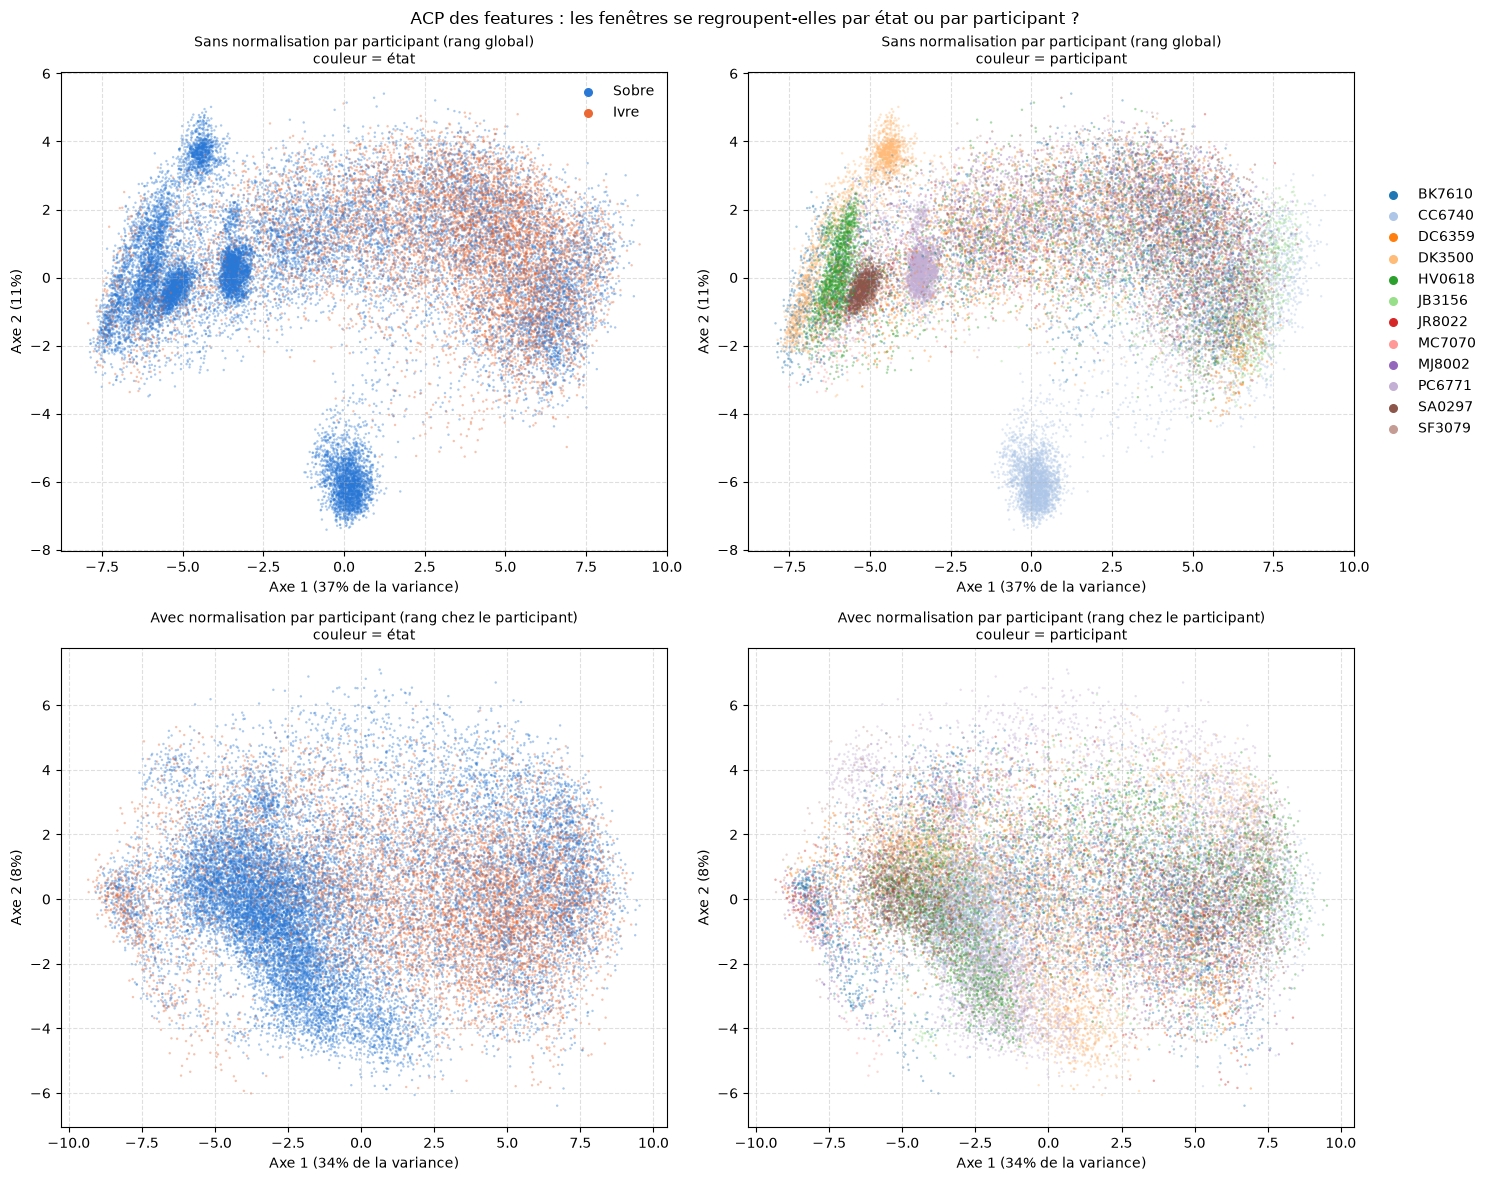

In [26]:
def projection_acp(tableau):
    """Projette les fenêtres sur les 2 premiers axes d'une ACP (après centrage-réduction)."""
    acp = PCA(n_components=2)
    points = acp.fit_transform(StandardScaler().fit_transform(tableau))
    return pd.DataFrame(points, index=tableau.index, columns=['axe_1', 'axe_2']), acp.explained_variance_ratio_


def part_expliquee(points, groupes):
    """Part de la dispersion des points due aux écarts entre groupes (0 = groupes mélangés, 1 = groupes séparés)."""
    ecart_au_centre = points - points.mean()
    centres = points.groupby(groupes).transform('mean') - points.mean()
    return (centres**2).sum().sum() / (ecart_au_centre**2).sum().sum()


pids = features.index.get_level_values('pid')
etats = features['ivre'].map({0: 'Sobre', 1: 'Ivre'})
versions = {
    'Sans normalisation par participant (rang global)': features[colonnes_features].rank(pct=True),
    'Avec normalisation par participant (rang chez le participant)': rangs[colonnes_features],
}

couleurs_etat = {'Sobre': BLEU, 'Ivre': ORANGE}
palette = plt.get_cmap('tab20')
couleurs_pid = {pid: palette(i) for i, pid in enumerate(selected_pids)}
melange = np.random.default_rng(0).permutation(len(features))    # ordre de tracé aléatoire

bilan_acp = {}
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ligne, (titre, tableau) in enumerate(versions.items()):
    points, variance_expliquee = projection_acp(tableau)
    bilan_acp[titre] = {'variance_axes_1_et_2': variance_expliquee.sum(),
                        'part_due_au_participant': part_expliquee(points, pids),
                        'part_due_a_l_etat': part_expliquee(points, etats.to_numpy())}
    p = points.iloc[melange]
    axes[ligne, 0].scatter(p['axe_1'], p['axe_2'], s=3, alpha=0.4, linewidths=0,
                           c=list(etats.iloc[melange].map(couleurs_etat)))
    axes[ligne, 1].scatter(p['axe_1'], p['axe_2'], s=3, alpha=0.4, linewidths=0,
                           c=[couleurs_pid[pid] for pid in pids[melange]])
    axes[ligne, 0].set_title(f'{titre}\ncouleur = état', fontsize=10)
    axes[ligne, 1].set_title(f'{titre}\ncouleur = participant', fontsize=10)
    for ax in axes[ligne]:
        ax.set_xlabel(f'Axe 1 ({variance_expliquee[0]:.0%} de la variance)')
        ax.set_ylabel(f'Axe 2 ({variance_expliquee[1]:.0%})')
        ax.grid(True, linestyle='--', alpha=0.4)

for nom, couleur in couleurs_etat.items():
    axes[0, 0].scatter([], [], s=30, color=couleur, label=nom)
axes[0, 0].legend(loc='upper right', frameon=False)
for pid, couleur in couleurs_pid.items():
    axes[0, 1].scatter([], [], s=30, color=couleur, label=pid)
axes[0, 1].legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)

fig.suptitle('ACP des features : les fenêtres se regroupent-elles par état ou par participant ?')
plt.tight_layout()
plt.show()

#display(pd.DataFrame(bilan_acp).T.round(2))

 - **Sans normalisation, les fenêtres se regroupent par participant, pas par état** : plusieurs participants forment des amas isolés : CC6740, DK3500, HV0618, PC6771 et SA0297. Un modèle entraîné sur ces features apprendrait d'abord à reconnaître la personne ou son téléphone.
 - **Avec normalisation par participant** : les participants se mélangent. C’est ce qui justifie la normalisation. Cependant on constate que l’état sobre / ivre reste mal séparé car nos 2 composantes principales n’expliquent que 42 % de la variance. Il faudra donc combiner nos features pour espérer avoir des résultats de prédictions corrects.

## 3.5 Analyse des features

**Objectifs** : 

1. **Redondance** : certaines features apportent la même information
2. **Séparation** : lesquelles distinguent les fenêtres sobres des fenêtres ivres ?
3. **Effet de l'activité** : les participants bougent davantage quand ils sont ivres ; une feature peut donc séparer les classes simplement parce qu'elle mesure l'activité.

*1. Features redondantes*

On calcule la corrélation entre toutes les features (sur les rangs par participant), puis on écarte toute feature corrélée à plus de 0,9 avec une feature déjà retenue.

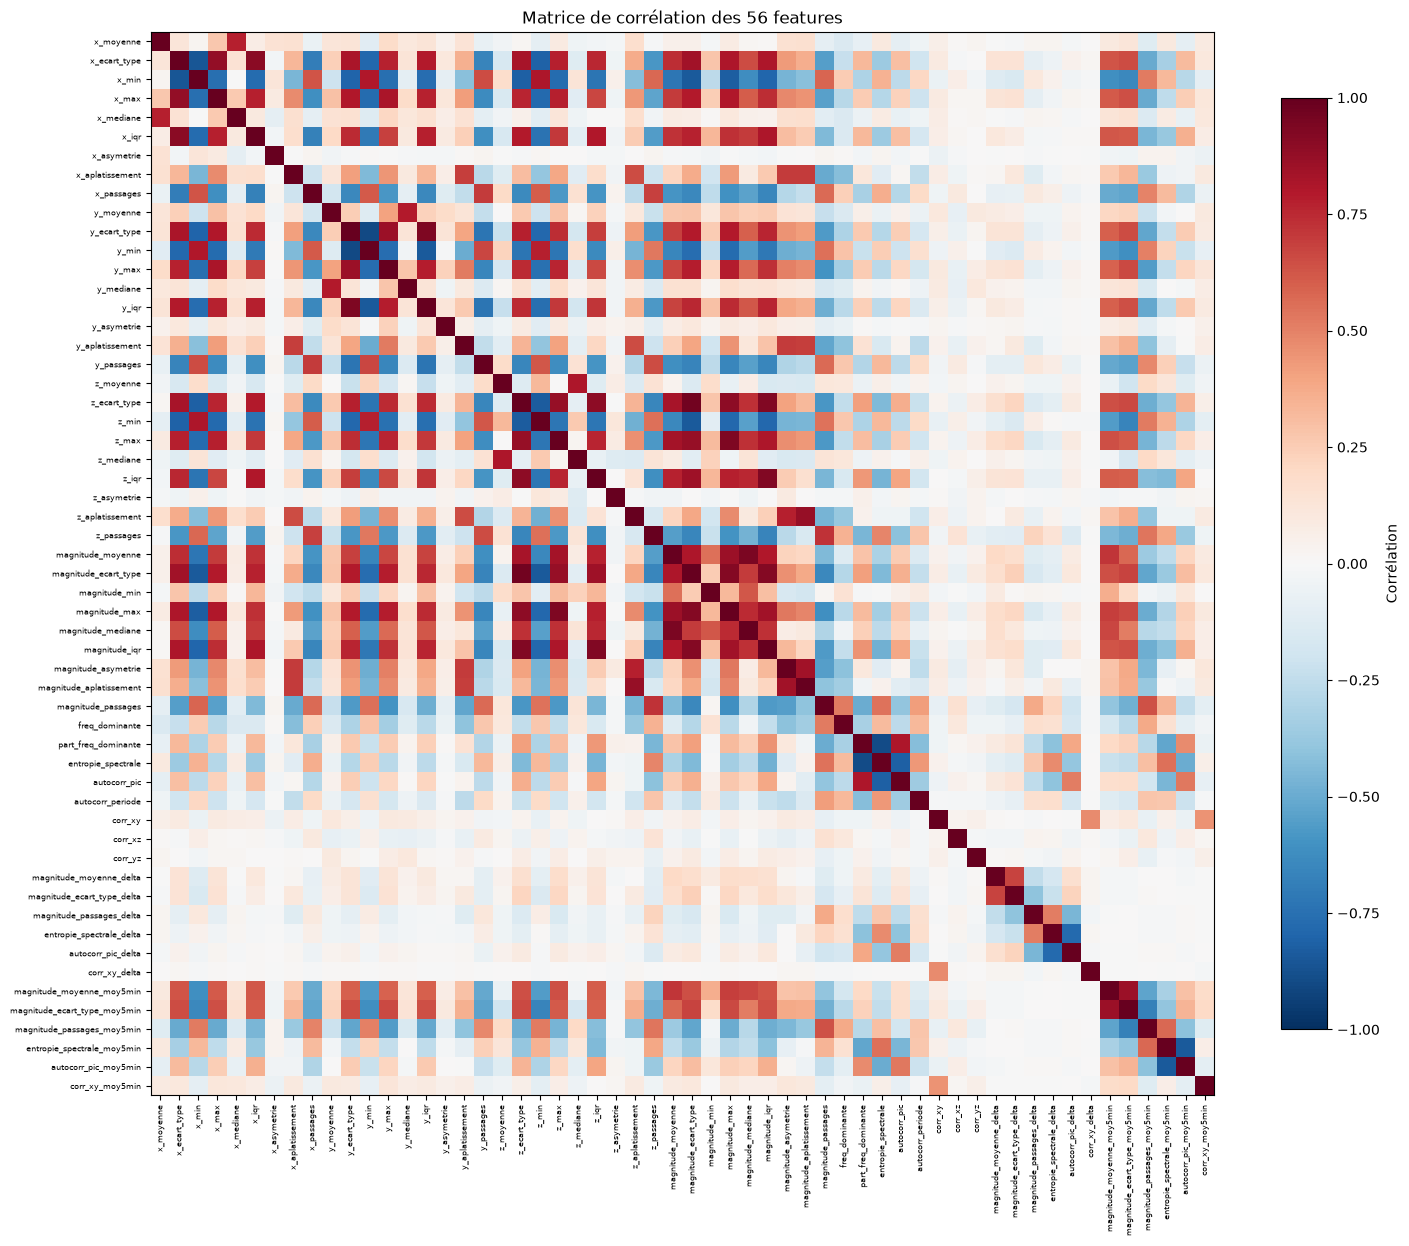

49 features retenues sur 56, 7 écartées


,doublon_de
magnitude_max,magnitude_ecart_type
magnitude_mediane,magnitude_moyenne
magnitude_iqr,magnitude_ecart_type
x_iqr,x_ecart_type
y_min,y_ecart_type
y_iqr,y_ecart_type
z_ecart_type,magnitude_ecart_type


In [27]:
SEUIL_REDONDANCE = 0.9

# Corrélation entre features, calculée sur les rangs par participant (corrélation de rang)
matrice = rangs.corr()

fig, ax = plt.subplots(figsize=(15, 13))
image = ax.imshow(matrice, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(matrice)))
ax.set_xticklabels(matrice.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(matrice)))
ax.set_yticklabels(matrice.columns, fontsize=6)
fig.colorbar(image, ax=ax, shrink=0.8, label='Corrélation')
ax.set_title(f'Matrice de corrélation des {len(matrice)} features')
plt.tight_layout()
plt.show()

# Ordre de parcours : features de la magnitude d'abord, puis les autres
ordre = ([f for f in colonnes_features if f.startswith('magnitude_')]
         + [f for f in colonnes_features if not f.startswith('magnitude_')])

features_retenues, ecartees = [], {}
for f in ordre:
    doublon = next((r for r in features_retenues if abs(matrice.loc[f, r]) > SEUIL_REDONDANCE), None)
    if doublon is None:
        features_retenues.append(f)
    else:
        ecartees[f] = doublon

print(f"{len(features_retenues)} features retenues sur {len(colonnes_features)}, {len(ecartees)} écartées")
display(pd.Series(ecartees, name='doublon_de').to_frame())

**On a retenu 49 features sur 56** : les 7 doublons écartés sont des mesures d'intensité ou de niveau déjà représentées (écart-type, écart interquartile, maximum, médiane).

*2. Séparation entre sobre et ivre*

**Notre métrique : l'AUC**, la probabilité qu'une fenêtre ivre ait une valeur plus élevée qu'une fenêtre sobre. 0,5 signifie aucune séparation ; plus elle s'approche de 1 ou de 0, plus la feature monte ou baisse nettement avec l'ivresse. 

Les features retenues sont regroupées en 7 familles, et on trace la plus séparante de chacune. Si même celle-là ne sépare rien, la famille n'apporte rien.

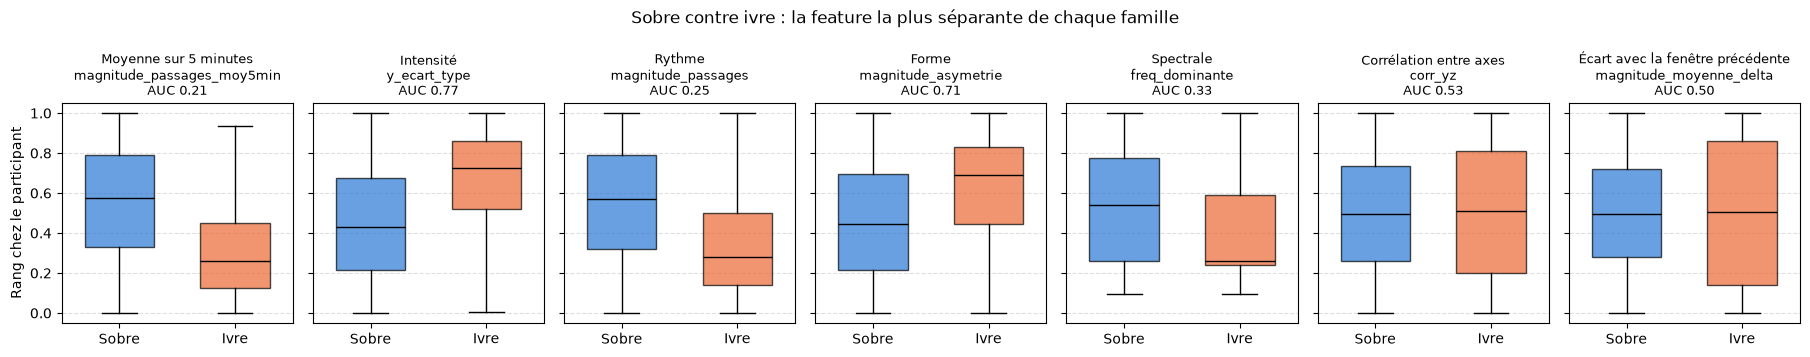

In [28]:
def auc(valeurs, ivre):
    """Probabilité qu'une fenêtre ivre tirée au hasard ait une valeur plus élevée qu'une fenêtre sobre."""
    rangs_valeurs = valeurs.rank()
    n_ivre = ivre.sum()
    n_sobre = len(ivre) - n_ivre
    return (rangs_valeurs[ivre == 1].sum() - n_ivre * (n_ivre + 1) / 2) / (n_ivre * n_sobre)


def auc_mediane(table, liste_features):
    """AUC de chaque feature, médiane sur les participants ayant les deux classes."""
    par_participant = pd.DataFrame({pid: {f: auc(table.loc[pid, f], table.loc[pid, 'ivre']) for f in liste_features}
                                    for pid in deux_classes})
    return par_participant.median(axis=1)


def famille(f):
    """Famille d'une feature, d'après son nom."""
    if f.endswith('_delta'):
        return 'Écart avec la fenêtre précédente'
    if f.endswith('_moy5min'):
        return 'Moyenne sur 5 minutes'
    if f.startswith('corr_'):
        return 'Corrélation entre axes'
    if f in colonnes_regularite:
        return 'Spectrale'
    statistique = f.split('_', 1)[1]
    if statistique in ('asymetrie', 'aplatissement'):
        return 'Forme'
    if statistique == 'passages':
        return 'Rythme'
    return 'Intensité'


def tracer_boxplots(selection, a_tracer, titres, titre_figure):
    """Box plots sobre / ivre des rangs par participant, pour les fenêtres sélectionnées."""
    sobre = rangs[selection & (features['ivre'] == 0).to_numpy()]
    ivre = rangs[selection & (features['ivre'] == 1).to_numpy()]
    fig, axes = plt.subplots(1, len(a_tracer), figsize=(2.6 * len(a_tracer), 3.6), sharey=True)
    for ax, f in zip(axes, a_tracer):
        boites = ax.boxplot([sobre[f], ivre[f]], widths=0.6, patch_artist=True, showfliers=False,
                            medianprops={'color': 'black'})
        for boite, couleur in zip(boites['boxes'], [BLEU, ORANGE]):
            boite.set_facecolor(couleur)
            boite.set_alpha(0.7)
        ax.set_xticks([1, 2])
        ax.set_xticklabels(['Sobre', 'Ivre'])
        ax.set_title(titres[f], fontsize=9)
        ax.grid(True, axis='y', linestyle='--', alpha=0.4)
    axes[0].set_ylabel('Rang chez le participant')
    fig.suptitle(titre_figure)
    plt.tight_layout()
    plt.show()


# Participants ayant au moins 150 fenêtres dans chaque classe
effectifs = features.groupby('pid')['ivre'].agg(ivre='sum', total='size')
deux_classes = effectifs[(effectifs['ivre'] >= 150) & (effectifs['total'] - effectifs['ivre'] >= 150)].index
avec_deux_classes = features.index.get_level_values('pid').isin(deux_classes)

# AUC médiane des features retenues, puis la plus séparante de chaque famille
separation = pd.DataFrame({'famille': [famille(f) for f in features_retenues],
                           'auc_mediane': auc_mediane(features, features_retenues)}, index=features_retenues)
separation['ecart_a_0.5'] = (separation['auc_mediane'] - 0.5).abs()
meilleures = separation.sort_values('ecart_a_0.5', ascending=False).groupby('famille').head(1)
meilleures = meilleures.sort_values('ecart_a_0.5', ascending=False)

A_TRACER = list(meilleures.index)
tracer_boxplots(avec_deux_classes, A_TRACER,
                {f: f"{meilleures.loc[f, 'famille']}\n{f}\nAUC {meilleures.loc[f, 'auc_mediane']:.2f}" for f in A_TRACER},
                'Sobre contre ivre : la feature la plus séparante de chaque famille')

**Cinq familles séparent en partie, deux ne séparent rien**

- **Les deux familles les plus séparantes** sont l'activité moyenne sur 5 minutes et l'intensité du mouvement. Globalement, en état d'ivresse, le mouvement est plus ample, plus asymétrique, plus lent et moins saccadé. 
- **La corrélation entre axes et l'écart avec la fenêtre précédente** ne séparent rien.

Même les meilleures features se chevauchent largement, le modèle devra donc les combiner.

*3. À activité égale : les fenêtres où le téléphone bouge*

On fait la même comparaison, restreinte à la moitié la plus agitée des fenêtres de chaque participant.
On ne compare plus activité et repos, mais des moments d'activité entre eux. Une feature qui sépare encore les classes capte autre chose que le simple fait de bouger.

,auc_toutes_fenetres,auc_telephone_bouge
magnitude_passages_moy5min,0.21,0.34
y_ecart_type,0.77,0.58
magnitude_passages,0.25,0.42
magnitude_asymetrie,0.71,0.55
freq_dominante,0.33,0.41
corr_yz,0.53,0.51
magnitude_moyenne_delta,0.50,0.50


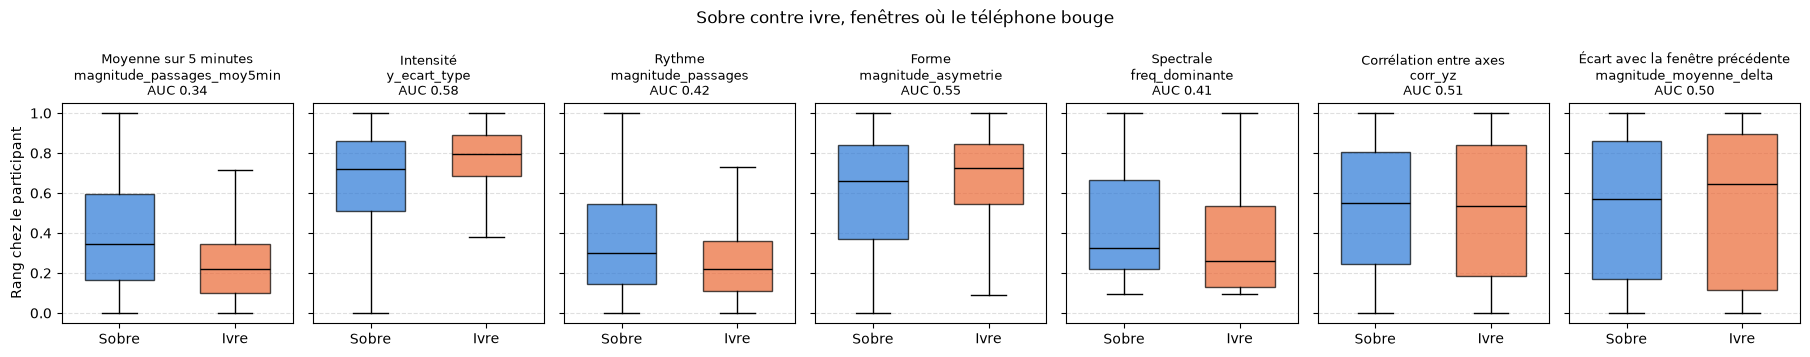

In [29]:
# Fenêtres où le téléphone bouge : la moitié la plus agitée des fenêtres de chaque participant
telephone_bouge = (rangs['magnitude_ecart_type'] > 0.5).to_numpy()
auc_bouge = auc_mediane(features[telephone_bouge], A_TRACER)

display(pd.DataFrame({'auc_toutes_fenetres': meilleures['auc_mediane'],
                      'auc_telephone_bouge': auc_bouge}).round(2))

tracer_boxplots(avec_deux_classes & telephone_bouge, A_TRACER,
                {f: f"{meilleures.loc[f, 'famille']}\n{f}\nAUC {auc_bouge[f]:.2f}" for f in A_TRACER},
                'Sobre contre ivre, fenêtres où le téléphone bouge')


- **Seule la fréquence dominante sépare encore** : c'est la seule feature qui semble capter autre chose que l'activité. Pour les autres, elles semblaient surtout séparer les moments d'activité et de repos.
Le modèle risque donc de détecter que la personne bouge plutôt qu'elle est ivre.

## 3.6 Bilan du feature engineering

- **Nettoyage** : 10,4 millions de mesures conservées, pour 12 participants.
- **Échantillons** : 26 306 fenêtres de 10 s, dont 29 % en état d'ivresse ; 8 participants ont les deux classes en quantité suffisante.
- **Features** : 56 calculées, 49 retenues après suppression des doublons, normalisées par le rang au sein de chaque participant.
- **Signal** : les features séparent les classes surtout à travers l'activité ; la fréquence dominante est la seule à résister à activité égale.
- **Conséquence pour l'apprentissage** : évaluer participant par participant, et comparer les modèles à une référence fondée sur l'activité seule.

# <a id="dim"></a> 4. LEARNING

## 4.1 Formulation du problème

**Objectif** : classer chaque fenêtre de 10 s en sobre ou ivre (TAC ≥ 0,08 g/dl). C'est une classification binaire.

**Données** : 26 306 fenêtres, 49 features normalisées par participant, 29 % de fenêtres ivres.

**Validation croisée** : le modèle est entraîné sur 11 participants et prédit le 12ᵉ, pour chacun tour à tour. Un découpage aléatoire mettrait des fenêtres voisines d'une même personne à la fois en entraînement et en test : le modèle reconnaîtrait la personne. Ici, le score mesure la capacité à généraliser à une personne inconnue.

## 4.2 Choix des algorithmes

On compare quatre modèles :

| Modèle | Forces | Limites |
|---|---|---|
| **Régression logistique** | linéaire, rapide, interprétable : chaque feature reçoit un coefficient | ne capte pas les interactions non linéaires entre features, sauf si on les ajoute à la main |
| **SVM** | très efficace pour trouver des frontières de décision complexes grâce aux noyaux | coûteux en calcul sur 26 000 fenêtres, délicat à régler (paramètres C et γ) |
| **Gradient boosting** | construit des arbres successifs qui corrigent les erreurs des précédents ; performant sur des données en tableau | surapprend si le nombre d'arbres et le taux d'apprentissage ne sont pas maîtrisés |
| **Forêt aléatoire** | robuste au bruit, capte les interactions non linéaires, moins sensible au surapprentissage qu'un arbre seul | moins interprétable qu'une régression logistique |


## 4.3 Choix des métriques et référence

Avec 29 % de fenêtres ivres, répondre « sobre » à tout donnerait 71 % de bonnes réponses : l'*accuracy* est trompeuse. Pour comparer nos quatre modèles, nous analyserons 4 métriques dans un ordre précis :

 - **AUROC** : on la regarde en premier pour évaluer la capacité intrinsèque de chaque modèle à séparer les deux classes (sobre vs ivre), indépendamment du seuil de décision choisi. Elle permet d'éliminer immédiatement les modèles qui ne sépare pas clairement les classes.
 - **Exactitude Équilibrée** : pour mesurer le taux moyen de bonnes prédictions sur l'ensemble des deux classes, en surmontant le biais du déséquilibre de nos données (29 % d'ivresse) que l'accuracy classique ne corrige pas
 - **Rappel** : pour vérifier la capacité du modèle à capturer le maximum de véritables épisodes d'ivresse, ce qui est critique pour ne pas rater un utilisateur nécessitant une intervention de santé.
 - **Précision** : on la contrôle en dernier pour s'assurer que les alertes d'ivresse sont fiables et éviter de perturber inutilement un utilisateur sobre avec des notifications répétées.

**Référence à battre** : une régression logistique sur une seule feature, l'activité moyenne des 5 dernières minutes (`magnitude_ecart_type_moy5min`). Un modèle qui ne la dépasse pas nettement détecte l'activité, pas l'ivresse.

**Hyperparamètres** : chaque modèle est réglé avant d'être évalué ; la méthode et les résultats sont présentés en section 5.

**Code commun à chaque méthode** : Initialisation des métriques, préparation des données par la validation croisée et définition du modèle de référence.

In [30]:
# Données d'apprentissage : features retenues, normalisées par participant
X = features_normalisees[features_retenues]
y = features_normalisees['ivre']
groupes = features_normalisees.index.get_level_values('pid')

print(f"{X.shape[0]} fenêtres x {X.shape[1]} features, {y.mean():.1%} en état d'ivresse, "
      f"{groupes.nunique()} participants")

26306 fenêtres x 49 features, 29.0% en état d'ivresse, 12 participants


In [31]:
validation = LeaveOneGroupOut()    # évaluation : un pli par participant
reglage = GroupKFold(n_splits=4)   # réglage des hyperparamètres : 4 groupes de 3 participants

resultats, predictions, grilles = {}, {}, {}


def metriques(y_vrai, prediction, score):
    """Accuracy, exactitude équilibrée, précision, rappel et AUROC."""
    return pd.Series({
        'accuracy': accuracy_score(y_vrai, prediction),
        'exactitude_equilibree': balanced_accuracy_score(y_vrai, prediction),
        'precision': precision_score(y_vrai, prediction, zero_division=0),
        'rappel': recall_score(y_vrai, prediction, zero_division=0),
        'auroc': roc_auc_score(y_vrai, score),
    })


def evaluer(nom, modele, X_eval=None):
    """Prédit chaque participant avec le modèle entraîné sur les autres, puis calcule les métriques."""
    X_eval = X if X_eval is None else X_eval
    # Score de chaque fenêtre : probabilité d'être ivre, ou distance à la frontière pour le SVM
    methode = 'predict_proba' if hasattr(modele, 'predict_proba') else 'decision_function'
    score = cross_val_predict(modele, X_eval, y, groups=groupes, cv=validation, method=methode, n_jobs=-1)
    score, seuil = (score[:, 1], 0.5) if methode == 'predict_proba' else (score, 0.0)
    prediction = (score >= seuil).astype(int)
    predictions[nom] = pd.DataFrame({'ivre': y, 'score': score, 'prediction': prediction}, index=X.index)
    resultats[nom] = metriques(y, prediction, score)
    return resultats[nom]


def scores_par_participant(nom):
    """Métriques de chaque participant ; non définies pour ceux qui n'ont qu'une seule classe."""
    lignes = {}
    for pid, d in predictions[nom].groupby(level='pid'):
        ligne = pd.Series({'fenetres': len(d), 'part_ivre': d['ivre'].mean()})
        if 0 < d['ivre'].mean() < 1:
            ligne = pd.concat([ligne, metriques(d['ivre'], d['prediction'], d['score']).drop('accuracy')])
        lignes[pid] = ligne
    colonnes = ['fenetres', 'part_ivre', 'exactitude_equilibree', 'precision', 'rappel', 'auroc']
    return pd.DataFrame(lignes).T.reindex(columns=colonnes)


def regler(nom, modele, grille, positions=None):
    """Teste chaque combinaison d'hyperparamètres (AUROC moyenne sur 4 groupes de participants)
    et renvoie le modèle avec la meilleure combinaison. Les résultats sont analysés en section 5."""
    positions = np.arange(len(X)) if positions is None else positions
    recherche = GridSearchCV(modele, grille, scoring='roc_auc', cv=reglage, n_jobs=-1, refit=False)
    recherche.fit(X.iloc[positions], y.iloc[positions], groups=groupes[positions])
    tableau = pd.DataFrame(recherche.cv_results_['params'])
    tableau['auroc_moyenne'] = recherche.cv_results_['mean_test_score']
    tableau['ecart_type'] = recherche.cv_results_['std_test_score']
    grilles[nom] = tableau.sort_values('auroc_moyenne', ascending=False)
    print(f"{nom} : meilleure combinaison {recherche.best_params_} "
          f"(AUROC moyenne de réglage {recherche.best_score_:.3f})")
    return clone(modele).set_params(**recherche.best_params_)


COLONNES_SCORES = ['auroc', 'exactitude_equilibree', 'precision', 'rappel']

# Référence : une seule feature, l'activité moyenne sur les 5 dernières minutes
evaluer('Référence', LogisticRegression(class_weight='balanced', max_iter=1000),
        X[['magnitude_ecart_type_moy5min']])
display(pd.DataFrame(resultats).T[COLONNES_SCORES].round(3))

,auroc,exactitude_equilibree,precision,rappel
Référence,0.625,0.612,0.389,0.63


## 4.4 Régression logistique

La régression logistique donne un coefficient à chaque feature et additionne leurs contributions pour calculer la probabilité qu'une fenêtre soit ivre. La frontière entre les deux classes est donc un plan : c'est le modèle le plus simple, et il sert de point de comparaison aux modèles non linéaires. On utilise une régularisation L2, qui empêche les coefficients de devenir trop grands quand les features sont corrélées.

**Hyperparamètre** : `C`, l'inverse de la force de régularisation. Petit, le modèle reste simple ; grand, il colle aux données d'entraînement.

In [32]:
regression_logistique = regler('Régression logistique',
                               LogisticRegression(class_weight='balanced', max_iter=2000),
                               {'C': [0.0001, 0.001, 0.01, 0.1, 1, 10]})
evaluer('Régression logistique', regression_logistique)
display(pd.DataFrame(resultats).T[COLONNES_SCORES].round(3))

Régression logistique : meilleure combinaison {'C': 0.001} (AUROC moyenne de réglage 0.686)


,auroc,exactitude_equilibree,precision,rappel
Référence,0.625,0.612,0.389,0.630
Régression logistique,0.662,0.670,0.453,0.672


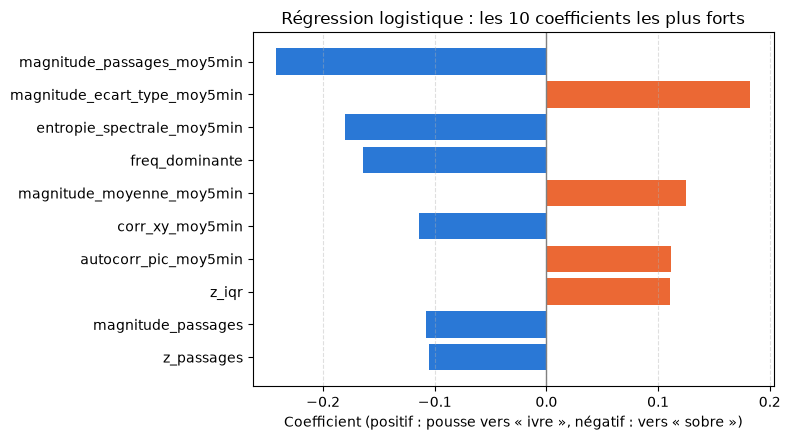

In [33]:
# Coefficients du modèle entraîné sur tous les participants (pour l'interprétation uniquement)
regression_logistique.fit(X, y)
coefficients = pd.Series(regression_logistique.coef_[0], index=features_retenues)
principaux = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(10)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(principaux.index[::-1], principaux[::-1],
        color=[ORANGE if c > 0 else BLEU for c in principaux[::-1]])
ax.axvline(0, color='gray', linewidth=1)
ax.set_xlabel("Coefficient (positif : pousse vers « ivre », négatif : vers « sobre »)")
ax.set_title('Régression logistique : les 10 coefficients les plus forts')
ax.grid(True, axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

#display(principaux.round(2).to_frame('coefficient'))

## 4.5 SVM à noyau RBF

Un SVM cherche la frontière qui sépare les deux classes avec la plus grande marge. Le noyau RBF lui permet de tracer une frontière courbe, en comparant chaque fenêtre aux fenêtres d'entraînement voisines.

**Hyperparamètres**

- **`C`** : la tolérance aux erreurs d'entraînement. Petit, la frontière reste simple ; grand, elle risque de surapprendre.
- **`gamma`** : la portée de l'influence de chaque fenêtre. Petit, la frontière est lisse ; grand, elle devient sinueuse et suit le bruit.

In [34]:
echantillon = np.random.default_rng(0).choice(len(X), size=5000, replace=False)
svm = regler('SVM', SVC(kernel='rbf', class_weight='balanced', cache_size=1000),
             {'C': [0.01, 0.03, 0.1, 0.3, 1, 10], 'gamma': ['scale', 0.05, 1]}, positions=echantillon)
evaluer('SVM', svm)
display(pd.DataFrame(resultats).T[COLONNES_SCORES].round(3))

SVM : meilleure combinaison {'C': 0.3, 'gamma': 'scale'} (AUROC moyenne de réglage 0.755)


,auroc,exactitude_equilibree,precision,rappel
Référence,0.625,0.612,0.389,0.630
Régression logistique,0.662,0.670,0.453,0.672
SVM,0.762,0.709,0.443,0.862


## 4.6 Gradient boosting

Le gradient boosting construit des arbres de décision les uns après les autres, chacun corrigeant les erreurs des précédents. On utilise `HistGradientBoostingClassifier`, qui regroupe les valeurs en intervalles pour aller plus vite. 

**Hyperparamètres**

- **`learning_rate`** : le poids de chaque nouvel arbre. Petit, l'apprentissage est lent mais stable.
- **`max_iter`** : le nombre d'arbres. Trop d'arbres finissent par apprendre le bruit.
- **`max_depth`** : la profondeur des arbres, donc la complexité des interactions captées.

In [35]:
boosting = regler('Gradient boosting',
                  HistGradientBoostingClassifier(class_weight='balanced', early_stopping=False, random_state=0),
                  {'learning_rate': [0.01, 0.03, 0.1], 'max_iter': [100, 300, 600], 'max_depth': [3, 6, None]})
evaluer('Gradient boosting', boosting)
display(pd.DataFrame(resultats).T[COLONNES_SCORES].round(3))

Gradient boosting : meilleure combinaison {'learning_rate': 0.03, 'max_depth': 6, 'max_iter': 600} (AUROC moyenne de réglage 0.764)


,auroc,exactitude_equilibree,precision,rappel
Référence,0.625,0.612,0.389,0.630
Régression logistique,0.662,0.670,0.453,0.672
SVM,0.762,0.709,0.443,0.862
Gradient boosting,0.753,0.682,0.483,0.646


## 4.7 Random Forest

Une forêt aléatoire entraîne de nombreux arbres de décision indépendants, chacun sur un tirage aléatoire des fenêtres et des features, puis fait voter les arbres. Moyenner des arbres différents réduit le surapprentissage d'un arbre seul.

**Hyperparamètres**

- **`n_estimators`** : le nombre d'arbres. Ajouter des arbres ne fait pas surapprendre, mais le gain finit par plafonner.
- **`min_samples_leaf`** : la taille minimale des feuilles. Petite, les arbres sont détaillés et risquent de surapprendre ; grande, ils restent généraux.
- **`max_features`** : le nombre de features tirées à chaque découpage. Peu, les arbres sont plus variés ; beaucoup, ils sont plus précis mais se ressemblent.

In [36]:
foret = regler('Forêt aléatoire',
               RandomForestClassifier(class_weight='balanced', random_state=0, n_jobs=1),
               {'n_estimators': [100, 300], 'min_samples_leaf': [50, 100, 200], 'max_features': [3, 'sqrt', 15]})
evaluer('Forêt aléatoire', foret)
display(pd.DataFrame(resultats).T[COLONNES_SCORES].round(3))

Forêt aléatoire : meilleure combinaison {'max_features': 3, 'min_samples_leaf': 50, 'n_estimators': 300} (AUROC moyenne de réglage 0.772)


,auroc,exactitude_equilibree,precision,rappel
Référence,0.625,0.612,0.389,0.630
Régression logistique,0.662,0.670,0.453,0.672
SVM,0.762,0.709,0.443,0.862
Gradient boosting,0.753,0.682,0.483,0.646
Forêt aléatoire,0.762,0.700,0.458,0.778


## 4.8 Comparaison des modèles

| Modèle | AUROC | Exactitude équilibrée | Précision | Rappel |
|---|---|---|---|---|
| **SVM (retenu)** | **0,762** | **70,9 %** | 44,3 % | 86,2 % |
| Forêt aléatoire | 0,762 | 70,0 % | 45,8 % | 77,8 % |
| Gradient boosting | 0,753 | 68,2 % | 48,3 % | 64,6 % |
| Régression logistique | 0,662 | 67,0 % | 45,3 % | 67,2 % |
| Référence (activité seule) | 0,625 | 61,2 % | 38,9 % | 63,0 % |


**SVM et forêt aléatoire en tête, à égalité**

- **Les trois modèles non linéaires se valent en AUROC** (environ 76%), nettement au-dessus de la régression logistique (66%) et de la référence (63%).
- **L'exactitude équilibrée départage de peu le SVM** : 71 %, contre 70 % pour la forêt aléatoire.
- **Les compromis diffèrent** : le SVM détecte la grande majorité des fenêtres ivres (86%) au prix de nombreuses fausses alertes (précision de 44%); le gradient boosting fait mieux (48% de précision) au prix d'une performance dégradée sur le rappel (65%).
- **Les alertes restent peu fiables** : aucun modèle ne dépasse 49 % de précision, soit plus d'une fausse alerte sur deux.

**Modèle retenu : le SVM** (`C = 0,3`), la forêt aléatoire restant une alternative équivalente. Relever son seuil de décision réduirait les fausses alertes, au prix d'épisodes ratés.

*Deux vérifications*

L'AUROC du tableau mélange les fenêtres de tous les participants. Deux questions restent ouvertes :

- **Le modèle fonctionne-t-il pour une personne donnée ?** En usage réel, il suivrait une seule personne : on calcule l'AUROC de chaque participant, puis leur médiane.
- **Détecte-t-il autre chose que l'activité ?** On recalcule l'AUROC sur les seules fenêtres où le téléphone bouge (3.5).

In [37]:
bouge = pd.Series(telephone_bouge, index=features.index).reindex(X.index).to_numpy()
verifications = pd.DataFrame({
    'auroc_mediane_par_participant': {nom: scores_par_participant(nom)['auroc'].median() for nom in predictions},
    'auroc_telephone_bouge': {nom: roc_auc_score(p['ivre'][bouge], p['score'][bouge])
                              for nom, p in predictions.items()},
}).loc[pd.DataFrame(resultats).T.sort_values('auroc', ascending=False).index]
display(verifications.round(3))

,auroc_mediane_par_participant,auroc_telephone_bouge
Forêt aléatoire,0.677,0.674
SVM,0.674,0.681
Gradient boosting,0.630,0.674
Régression logistique,0.713,0.619
Référence,0.733,0.585


- **Pour une personne donnée, aucun modèle ne bat la référence** : AUROC médiane de 0,73 pour la référence, de 0,63 à 0,71 pour les modèles. Leur avantage global ne vient pas d'un meilleur classement des fenêtres d'une même personne.
- **À activité égale, les modèles non linéaires gardent l'avantage** (environ 0,68 contre 0,59) : ils captent un peu plus que le simple fait de bouger.
- **Conséquence** : le choix du SVM parmi les modèles non linéaires est confirmé, mais leur intérêt reste limité. Le signal est réel mais faible, et ne fait pas mieux que l'activité pour suivre une personne en particulier.

# <a id="dim"></a> 5. HYPER PARAMETERS TUNING

Un **hyperparamètre** est un réglage fixé avant l'apprentissage. Le projet en a de deux sortes : ceux des **modèles** (régularisation, `C` et `gamma` du SVM, nombre et taille des arbres) et ceux du **feature engineering** (durée des fenêtres, seuil de remplissage).

**Méthode** : chaque combinaison est évaluée par l'AUROC moyenne d'une validation croisée en 4 groupes de 3 participants, avec entraînement sur 9 participants et évaluation sur les 3 autres. On retient la meilleure ; si elle tombe au bord de la plage testée, la plage est élargie.

**Limite** : les mêmes participants servent au réglage puis à l'évaluation (section 4), ce qui rend les scores finaux légèrement optimistes.

## 5.1 Hyperparamètres des modèles

Les tableaux donnent l'AUROC moyenne de réglage de chaque combinaison testée en section 4. Plus la valeur est haute, meilleure est la combinaison.

In [38]:
def tableau_grille(nom, lignes, colonnes):
    """Tableau croisé des AUROC moyennes de réglage d'un modèle."""
    g = grilles[nom].copy()
    for c in g.columns.drop(['auroc_moyenne', 'ecart_type']):
        g[c] = g[c].astype(object).where(g[c].notna(), 'illimitée')
    return g.pivot_table(index=lignes, columns=colonnes, values='auroc_moyenne', aggfunc='first').round(3)


print('Régression logistique : AUROC moyenne selon C')
display(grilles['Régression logistique'].set_index('C')['auroc_moyenne'].sort_index().round(3).to_frame().T)
print('SVM : AUROC moyenne selon C (lignes) et gamma (colonnes)')
display(tableau_grille('SVM', 'C', 'gamma'))
print('Gradient boosting : AUROC moyenne selon le taux d\'apprentissage et le nombre d\'arbres (lignes), et la profondeur (colonnes)')
display(tableau_grille('Gradient boosting', ['learning_rate', 'max_iter'], 'max_depth'))
print('Forêt aléatoire : AUROC moyenne selon le nombre d\'arbres et la taille minimale des feuilles (lignes), et le nombre de features par découpage (colonnes)')
display(tableau_grille('Forêt aléatoire', ['n_estimators', 'min_samples_leaf'], 'max_features'))

# Récapitulatif : meilleure combinaison de chaque modèle et son score
recapitulatif = pd.DataFrame({
    nom: {'meilleure_combinaison': {k: v for k, v in grilles[nom].iloc[0].items()
                                    if k not in ('auroc_moyenne', 'ecart_type')},
          'auroc_reglage': round(grilles[nom]['auroc_moyenne'].iloc[0], 3),
          'auroc_evaluation_par_participant': round(resultats[nom]['auroc'], 3)}
    for nom in grilles}).T
display(recapitulatif)

Régression logistique : AUROC moyenne selon C


C,0.0001,0.0010,0.0100,0.1000,1.0000,10.0000
auroc_moyenne,0.681,0.686,0.684,0.678,0.675,0.674


SVM : AUROC moyenne selon C (lignes) et gamma (colonnes)


gamma,0.05,1,scale
C,,,
0.01,0.692,0.743,0.720
0.03,0.696,0.743,0.733
0.10,0.707,0.745,0.748
0.30,0.726,0.750,0.755
1.00,0.741,0.739,0.743
10.00,0.723,0.730,0.694


Gradient boosting : AUROC moyenne selon le taux d'apprentissage et le nombre d'arbres (lignes), et la profondeur (colonnes)


max_depth                 3.0    6.0  illimitée
learning_rate max_iter                         
0.01          100       0.713  0.730      0.735
              300       0.738  0.758      0.757
              600       0.744  0.760      0.759
0.03          100       0.740  0.756      0.756
              300       0.746  0.762      0.756
              600       0.751  0.764      0.756
0.10          100       0.747  0.762      0.759
              300       0.753  0.756      0.755
              600       0.759  0.750      0.755

Forêt aléatoire : AUROC moyenne selon le nombre d'arbres et la taille minimale des feuilles (lignes), et le nombre de features par découpage (colonnes)


max_features                       3     15   sqrt
n_estimators min_samples_leaf                     
100          50                0.768  0.739  0.758
             100               0.768  0.749  0.767
             200               0.764  0.751  0.770
300          50                0.772  0.741  0.759
             100               0.772  0.747  0.765
             200               0.769  0.754  0.769

,meilleure_combinaison,auroc_reglage,auroc_evaluation_par_participant
Régression logistique,{'C': 0.001},0.686,0.662
SVM,"{'C': 0.3, 'gamma': 'scale'}",0.755,0.762
Gradient boosting,"{'learning_rate': 0.03, 'max_depth': 6.0, 'max...",0.764,0.753
Forêt aléatoire,"{'max_features': 3, 'min_samples_leaf': 50, 'n...",0.772,0.762


**Les réglages comptent peu, et favorisent les configurations simples**

- **Régression logistique** : l'AUROC est quasi constante ; la meilleure valeur correspond à une régularisation forte.
- **SVM** : c'est le modèle le plus sensible à son réglage. Les extrêmes donnent une frontière trop simple ou trop ajustée ; l'optimum est intermédiaire.
- **Gradient boosting** : seuls les modèles trop simples (arbres peu profonds, peu d'arbres) décrochent ; au-delà, l'AUROC plafonne.
- **Forêt aléatoire** : le gain plafonne dès 100 arbres ; tirer peu de features à chaque découpage, donc des arbres plus variés, généralise mieux.
- **Conséquence** : sur un signal faible et bruité, la complexité n'apporte rien et risque de faire apprendre le bruit. Les écarts entre réglage et évaluation, de l'ordre de 0,01, sont du même ordre que les écarts entre modèles non linéaires : impossible de les départager finement.

## 5.2 Hyperparamètres du feature engineering

*Durée des fenêtres et seuil de remplissage*

Plusieurs valeurs sont comparées sur des critères de données : nombre de fenêtres, heures de signal, part de mesures conservées et part de fenêtres ivres.

In [39]:
DUREES_S = [5, 10, 20, 30]
SEUILS_REMPLISSAGE = [0.5, 0.8, 0.95]

# Écart médian entre deux mesures de chaque téléphone (20, 25, 26 ou 45 ms), pour calculer le remplissage
ecart_median_ms = data.groupby('pid')['time'].apply(lambda t: t.sort_values().diff().median())


lignes_donnees = []
for duree_s in DUREES_S:
    duree_ms = duree_s * 1000
    fen = data.groupby([data['pid'], data['time'] // duree_ms]).agg(n=('time', 'size'), t=('time', 'mean'))
    fen['remplissage'] = fen['n'] / fen.index.get_level_values('pid').map(duree_ms / ecart_median_ms)
    fen['tac'] = np.nan
    for pid in selected_pids:
        tac = charger_tac(pid)
        fen.loc[pid, 'tac'] = np.interp(fen.loc[pid, 't'] / 1000, tac['timestamp'], tac['TAC_Reading'])
    pids = fen.index.get_level_values('pid')
    for seuil in SEUILS_REMPLISSAGE:
        garde = fen['remplissage'] >= seuil
        lignes_donnees.append({
            'duree_s': duree_s,
            'remplissage_min': seuil,
            'fenetres': int(garde.sum()),
            'heures': round(garde.sum() * duree_s / 3600, 1),
            'mesures_gardees_%': round(100 * fen.loc[garde, 'n'].sum() / fen['n'].sum(), 1),
            'part_ivre_%': round(100 * (fen.loc[garde, 'tac'] >= SEUIL_TAC).mean(), 1),
        })

comparaison_donnees = pd.DataFrame(lignes_donnees).set_index(['duree_s', 'remplissage_min'])
display(comparaison_donnees)

fenetres  heures  mesures_gardees_%  part_ivre_%
duree_s remplissage_min                                                  
5       0.50                53848    74.8               99.0         29.4
        0.80                53120    73.8               98.0         29.2
        0.95                50763    70.5               93.8         29.7
10      0.50                26924    74.8               98.6         29.4
        0.80                26306    73.1               96.9         29.0
        0.95                25634    71.2               94.4         29.2
20      0.50                13440    74.7               97.9         29.4
        0.80                12995    72.2               95.5         28.9
        0.95                12821    71.2               94.2         28.8
30      0.50                 8922    74.4               97.3         29.4
        0.80                 8607    71.7               94.8         28.8
        0.95                 8478    70.6               93.4         28.7

**La durée de fenêtre change surtout le nombre d'exemples**

- **Le signal conservé varie peu** (de 71 à 75 heures), et le seuil de remplissage pèse plus que la durée.
- **La part de fenêtres ivres reste stable**, autour de 29 %.
- **Les fenêtres longues divisent le nombre d'exemples** : 3 fois moins à 30 s qu'à 10 s, pour le même signal.

## 5.3 Bilan des hyperparamètres

- **Les hyperparamètres des modèles comptent peu** : une fois les réglages trop simples écartés, l'AUROC varie de quelques centièmes, et les configurations retenues sont les plus simples, cohérentes avec un signal faible et bruité.
- **Les modèles non linéaires ne se départagent pas** : leurs écarts sont du même ordre que l'incertitude du réglage. Le SVM est retenu sur l'exactitude équilibrée ; la forêt aléatoire reste équivalente.
- **Feature engineering** : des fenêtres de 10 s remplies à 80 % conservent l'essentiel du signal, avec un nombre d'exemples suffisant.

# <a id="dim"></a> 6. CONCLUSION

## 6.1 Analyse des erreurs du modèle retenu

**Objectif** : savoir où se situent les erreurs du SVM par rapport au seuil d'ivresse. Une erreur sur une fenêtre dont le TAC est proche de 0,08 g/dl est attendue, puisque l'étiquette y est incertaine ; une erreur loin du seuil révèle une vraie limite du modèle. 

**Méthode** : on trace le TAC réel des fenêtres mal classées lors de l'évaluation participant par participant : les **faux positifs** (fenêtres sobres annoncées ivres) et les **faux négatifs** (fenêtres ivres annoncées sobres).

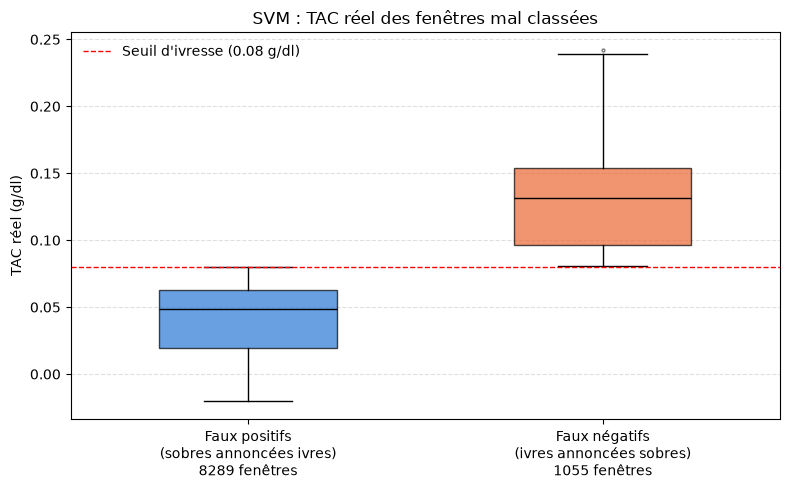

,fenetres,quartile_25,mediane,quartile_75,part_a_moins_de_0.02_du_seuil_%
Faux positifs,8289.0,0.020,0.049,0.063,31.572
Faux négatifs,1055.0,0.097,0.131,0.154,27.583


In [40]:
# TAC réel des fenêtres mal classées par le SVM, lors de l'évaluation participant par participant
erreurs_svm = predictions['SVM'].assign(tac=features_normalisees['tac'])
faux_positifs = erreurs_svm.loc[(erreurs_svm['prediction'] == 1) & (erreurs_svm['ivre'] == 0), 'tac']
faux_negatifs = erreurs_svm.loc[(erreurs_svm['prediction'] == 0) & (erreurs_svm['ivre'] == 1), 'tac']

fig, ax = plt.subplots(figsize=(8, 5))
boites = ax.boxplot([faux_positifs, faux_negatifs], widths=0.5, patch_artist=True,
                    medianprops={'color': 'black'}, flierprops={'markersize': 2, 'alpha': 0.3})
for boite, couleur in zip(boites['boxes'], [BLEU, ORANGE]):
    boite.set_facecolor(couleur)
    boite.set_alpha(0.7)
ax.axhline(SEUIL_TAC, color='red', linestyle='--', linewidth=1, label=f"Seuil d'ivresse ({SEUIL_TAC} g/dl)")
ax.set_xticks([1, 2])
ax.set_xticklabels([f'Faux positifs\n(sobres annoncées ivres)\n{len(faux_positifs)} fenêtres',
                    f'Faux négatifs\n(ivres annoncées sobres)\n{len(faux_negatifs)} fenêtres'])
ax.set_ylabel('TAC réel (g/dl)')
ax.set_title('SVM : TAC réel des fenêtres mal classées')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Quartiles du TAC réel, et part des erreurs proches du seuil (à moins de 0,02 g/dl)
display(pd.DataFrame({
    nom: {'fenetres': len(tac), 'quartile_25': tac.quantile(0.25), 'mediane': tac.median(),
          'quartile_75': tac.quantile(0.75),
          'part_a_moins_de_0.02_du_seuil_%': 100 * ((tac - SEUIL_TAC).abs() <= 0.02).mean()}
    for nom, tac in [('Faux positifs', faux_positifs), ('Faux négatifs', faux_negatifs)]}).T.round(3))

**Les erreurs ne se limitent pas aux fenêtres proches du seuil**

- **Huit fois plus de faux positifs que de faux négatifs** (environ 8 300 contre 1 100) : c'est le compromis du SVM, qui détecte presque toutes les fenêtres ivres au prix de nombreuses fausses alertes.
- **Faux positifs** : TAC réel médian de 0,05 g/dl. Seul un tiers se situe à moins de 0,02 du seuil, et un quart a un TAC inférieur à 0,02 : des fenêtres franchement sobres, annoncées ivres.
- **Faux négatifs** : TAC réel médian de 0,13 g/dl. Un quart dépasse 0,15 g/dl, près du double du seuil : des épisodes d'ivresse marquée, manqués.
- **Conséquence** : la plupart des erreurs ne s'expliquent pas par l'incertitude de l'étiquette autour du seuil. Ce sont de vraies limites du modèle, cohérentes avec un signal qui reflète surtout l'activité. 
Un tel outil ne peut pas servir dans des situations à conséquences sociales, comme un contrôle d'alcoolémie.

## 6.2 Bilan et pistes d'amélioration

Notre objectif initial était de classifier automatiquement des tranches de mouvements de 10 secondes en état « sobre » ou « ivre » à partir des seules données d’accéléromètre d’un smartphone. Après un nettoyage complet du jeu de données, la construction de variables caractérisant l'intensité, la forme et la régularité des signaux, ainsi que la comparaison rigoureuse de quatre modèles par validation croisée, le SVM s'impose comme le meilleur algorithme. Il atteint une AUROC de 76 % et une exactitude équilibrée de 71 %.

Cependant, ces résultats globaux masquent une limite majeure : la précision du modèle plafonne à 44 %, ce qui signifie que plus d'une alerte d'ivresse sur deux est un faux positif. En réalité, la séparation s’appuie presque exclusivement sur le niveau d'activité globale de l'utilisateur, et aucun modèle ne parvient à faire mieux que ce simple indicateur. En l'état, ces performances restent trop fragiles pour envisager un déploiement réel dans un contexte social ou juridique comme le contrôle du respect de la loi, où le coût d'une fausse accusation est inacceptable. Pour des applications de santé mobile (JITAIs), l'outil ne pourrait servir qu'à titre indicatif, en combinant plusieurs prédictions sur 1 à 2 minutes pour stabiliser la décision.

Ce manque de précision s'explique en grande partie par la qualité et la structure des données à notre disposition. D'une part, sur les 19 participants initiaux, seuls 12 présentaient des enregistrements exploitables, et seulement 8 ont effectivement alterné entre sobriété et ivresse au cours du suivi. D'autre part, la position exacte du téléphone (poche, sac, main ou table) et son orientation temporelle étaient totalement inconnues, rendant impossible toute association des axes d'accélération à une direction physique de déplacement. Pour surmonter ces contraintes, plusieurs pistes méthodologiques et matérielles devraient être envisagées à l'avenir : imposer un capteur unique pour tous les sujets afin d'éliminer les biais d'échantillonnage, isoler la marche réelle via les algorithmes natifs du téléphone, ajuster le seuil de décision du modèle selon le cas d'usage ciblé, ou encore collecter un volume de données plus vaste où chaque individu fournirait une période sobre de référence.

Enfin, notre travail ouvre la voie à deux perspectives majeures qui n'ont pas été explorées ici. Sur le plan de l'ingénierie des variables, nos deux principales caractéristiques n'expliquaient qu'environ 42 % de la variance, ce qui suggère une marge de progression importante. Il serait pertinent de tester les coefficients MFCC : bien que peu intuitifs et conçus à l'origine pour l'audio, ils constituent le principal gain de la littérature de référence et mériteraient d'être évalués sous une validation stricte par participant pour vérifier leur pouvoir de généralisation. Sur le plan algorithmique, l'utilisation d'architectures de Deep Learning (réseaux convolutifs ou récurrents) appliquées directement au signal brut permettrait d'apprendre des représentations complexes sans extraction manuelle, à condition toutefois de disposer d'un échantillon d'individus nettement plus vaste.